# Retail Product Price Optimization 

— Data Understanding, Data Quality & EDA

In [206]:
# IMPORT LIBRARIES

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error,root_mean_squared_error,mean_absolute_percentage_error

print("Modeling libraries imported successfully.")

print("Libraries imported successfully.")


Modeling libraries imported successfully.
Libraries imported successfully.


In [2]:
#load the dataset

df = pd.read_csv("retail_price.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (676, 30)


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500


In [3]:
# Basic data understanding

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


Rows: 676
Columns: 30

Column names:
['product_id', 'product_category_name', 'month_year', 'qty', 'total_price', 'freight_price', 'unit_price', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_score', 'customers', 'weekday', 'weekend', 'holiday', 'month', 'year', 's', 'volume', 'comp_1', 'ps1', 'fp1', 'comp_2', 'ps2', 'fp2', 'comp_3', 'ps3', 'fp3', 'lag_price']

Data types:


,dtype
product_id,object
product_category_name,object
month_year,object
qty,int64
total_price,float64
freight_price,float64
unit_price,float64
product_name_lenght,int64
product_description_lenght,int64
product_photos_qty,int64



First 5 rows:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500



Last 5 rows:


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
671,bed5,bed_bath_table,01-05-2017,1,215.0000,8.7600,215.0000,56,162,5,9750,4.4000,57,23,8,1,5,2017,0.6494,12600,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,214.9500
672,bed5,bed_bath_table,01-06-2017,10,"2,090.0000",21.3220,209.0000,56,162,5,9750,4.4000,61,22,8,1,6,2017,6.4935,12600,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,215.0000
673,bed5,bed_bath_table,01-07-2017,59,"12,095.0000",22.1959,205.0000,56,162,5,9750,4.4000,123,21,10,1,7,2017,38.3117,12600,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,209.0000
674,bed5,bed_bath_table,01-08-2017,52,"10,375.0000",19.4129,199.5098,56,162,5,9750,4.4000,90,23,8,1,8,2017,33.7662,12600,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,205.0000
675,bed5,bed_bath_table,01-09-2017,32,"5,222.3600",24.3247,163.3987,56,162,5,9750,4.4000,54,21,9,1,9,2017,20.7792,12600,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,199.5098


In [4]:
# Data Structure and Summary

print("Unique products:", df["product_id"].nunique())
print("Unique categories:", df["product_category_name"].nunique())
print("Unique periods:", df["month_year"].nunique())

print("\nProducts per category:")
display(df.groupby("product_category_name")["product_id"].nunique().sort_values(ascending=False).to_frame("unique_products"))

print("\nObservations per product:")
display(df.groupby("product_id").size().describe().to_frame("observations"))


Unique products: 52
Unique categories: 9
Unique periods: 20

Products per category:


,unique_products
product_category_name,
health_beauty,10
garden_tools,10
watches_gifts,8
computers_accessories,6
bed_bath_table,5
cool_stuff,5
furniture_decor,4
consoles_games,2
perfumery,2



Observations per product:


,observations
count,52.0000
mean,13.0000
std,3.7469
min,5.0000
25%,10.0000
50%,13.0000
75%,16.0000
max,20.0000


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,676,52,health7,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,676,9,garden_tools,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month_year,676,20,01-03-2018,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
qty,676.0000,NaN,NaN,NaN,14.4956,15.4434,1.0000,4.0000,10.0000,18.0000,122.0000
total_price,676.0000,NaN,NaN,NaN,"1,422.7087","1,700.1231",19.9000,333.7000,807.8900,"1,887.3225","12,095.0000"
freight_price,676.0000,NaN,NaN,NaN,20.6823,10.0818,0.0000,14.7619,17.5185,22.7136,79.7600
unit_price,676.0000,NaN,NaN,NaN,106.4968,76.1830,19.9000,53.9000,89.9000,129.9900,364.0000
product_name_lenght,676.0000,NaN,NaN,NaN,48.7204,9.4207,29.0000,40.0000,51.0000,57.0000,60.0000
product_description_lenght,676.0000,NaN,NaN,NaN,767.3994,655.2050,100.0000,339.0000,501.0000,903.0000,"3,006.0000"
product_photos_qty,676.0000,NaN,NaN,NaN,1.9941,1.4205,1.0000,1.0000,1.5000,2.0000,8.0000


In [6]:
# change date column to datetime format

df["date"] = pd.to_datetime(df["month_year"], format="%d-%m-%Y",errors="coerce")

print("Invalid dates:", df["date"].isna().sum())
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df[["month_year", "date"]].head())


Invalid dates: 0
Date range: 2017-01-01 00:00:00 to 2018-08-01 00:00:00


,month_year,date
0,01-05-2017,2017-05-01
1,01-06-2017,2017-06-01
2,01-07-2017,2017-07-01
3,01-08-2017,2017-08-01
4,01-09-2017,2017-09-01


# DATA QUALITY ASSESSMENT

In [7]:
# Check for missing values

missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
})

display(missing_report[missing_report["missing_count"] > 0])

if missing.sum() == 0:
    print("No missing values found.")


,missing_count,missing_percent


No missing values found.


In [8]:
# Check for duplicates

exact_duplicates = df.duplicated().sum()
product_period_duplicates = df.duplicated(
    subset=["product_id", "date"]
).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate product-period rows:", product_period_duplicates)

if product_period_duplicates > 0:
    display(
        df[df.duplicated(["product_id", "date"], keep=False)]
        .sort_values(["product_id", "date"])
    )


Exact duplicate rows: 0
Duplicate product-period rows: 0


In [9]:
# Numerical sanity checks

non_negative_columns = [
    "qty", "total_price", "freight_price", "unit_price",
    "product_name_lenght", "product_description_lenght",
    "product_photos_qty", "product_weight_g", "product_score",
    "customers", "weekday", "weekend", "holiday",
    "month", "year", "s", "volume",
    "comp_1", "ps1", "fp1",
    "comp_2", "ps2", "fp2",
    "comp_3", "ps3", "fp3",
    "lag_price"
]

negative_report = {}
for col in non_negative_columns:
    if col in df.columns:
        negative_report[col] = int((df[col] < 0).sum())

negative_report = pd.Series(negative_report).sort_values(ascending=False)
display(negative_report.to_frame("negative_count"))

print("\nColumns with negative values:")
display(negative_report[negative_report > 0].to_frame("negative_count"))


,negative_count
qty,0
total_price,0
freight_price,0
unit_price,0
product_name_lenght,0
product_description_lenght,0
product_photos_qty,0
product_weight_g,0
product_score,0
customers,0



Columns with negative values:


,negative_count


In [10]:
# Range / Summary Report

numeric_cols = df.select_dtypes(include=np.number).columns

summary = df[numeric_cols].describe().T
summary["missing"] = df[numeric_cols].isna().sum()
summary["unique"] = df[numeric_cols].nunique()

display(summary)


,count,mean,std,min,25%,50%,75%,max,missing,unique
qty,676.0000,14.4956,15.4434,1.0000,4.0000,10.0000,18.0000,122.0000,0,66
total_price,676.0000,"1,422.7087","1,700.1231",19.9000,333.7000,807.8900,"1,887.3225","12,095.0000",0,573
freight_price,676.0000,20.6823,10.0818,0.0000,14.7619,17.5185,22.7136,79.7600,0,653
unit_price,676.0000,106.4968,76.1830,19.9000,53.9000,89.9000,129.9900,364.0000,0,280
product_name_lenght,676.0000,48.7204,9.4207,29.0000,40.0000,51.0000,57.0000,60.0000,0,24
product_description_lenght,676.0000,767.3994,655.2050,100.0000,339.0000,501.0000,903.0000,"3,006.0000",0,46
product_photos_qty,676.0000,1.9941,1.4205,1.0000,1.0000,1.5000,2.0000,8.0000,0,7
product_weight_g,676.0000,"1,847.4985","2,274.8085",100.0000,348.0000,950.0000,"1,850.0000","9,750.0000",0,45
product_score,676.0000,4.0855,0.2320,3.3000,3.9000,4.1000,4.2000,4.5000,0,11
customers,676.0000,81.0281,62.0556,1.0000,34.0000,62.0000,116.0000,339.0000,0,94


In [11]:
# Product/Category Consistency

category_per_product = (
    df.groupby("product_id")["product_category_name"]
      .nunique()
      .sort_values(ascending=False)
)

print("Products belonging to more than one category:",
      (category_per_product > 1).sum())

if (category_per_product > 1).any():
    inconsistent_products = category_per_product[category_per_product > 1].index
    display(
        df[df["product_id"].isin(inconsistent_products)]
        [["product_id", "product_category_name", "date"]]
        .sort_values(["product_id", "date"])
    )


Products belonging to more than one category: 0


# Business consistency checks

In [12]:
# Total Price Consistency

df["calculated_total_price"] = df["qty"] * df["unit_price"]
df["total_price_difference"] = (
    df["total_price"] - df["calculated_total_price"]
)


df["total_price_matches"] = np.isclose(
    df["total_price"],
    df["calculated_total_price"],
    rtol=1e-6,
    atol=1e-6
)

print("Exact/near-exact matches:",
      df["total_price_matches"].sum(), "/", len(df))

print("Mismatch count:",
      (~df["total_price_matches"]).sum())

display(
    df["total_price_difference"].describe().to_frame("total_price_difference")
)

display(
    df.loc[~df["total_price_matches"],
           ["product_id", "date", "qty", "unit_price",
            "total_price", "calculated_total_price",
            "total_price_difference"]]
    .head(20)
)


Exact/near-exact matches: 597 / 676
Mismatch count: 79


,total_price_difference
count,676.0000
mean,0.4883
std,8.1153
min,-44.2909
25%,0.0000
50%,0.0000
75%,0.0000
max,147.5511


,product_id,date,qty,unit_price,total_price,calculated_total_price,total_price_difference
18,garden5,2017-05-01,20,97.5882,"1,956.0000","1,951.7647",4.2353
21,garden5,2017-08-01,7,97.3333,683.0000,681.3333,1.6667
48,garden7,2017-11-01,20,51.3222,"1,043.6000","1,026.4444",17.1556
49,garden7,2017-12-01,10,56.9778,571.8000,569.7778,2.0222
54,garden7,2018-05-01,9,52.9000,477.1000,476.1000,1.0000
64,health9,2017-08-01,28,23.3974,651.7200,655.1274,-3.4074
140,garden4,2017-11-01,69,53.7857,"3,711.7000","3,711.2143",0.4857
141,garden4,2017-12-01,44,55.7500,"2,468.6000","2,453.0000",15.6000
143,garden4,2018-02-01,48,50.3571,"2,411.2000","2,417.1429",-5.9429
146,garden4,2018-05-01,25,53.0579,"1,319.5000","1,326.4474",-6.9474


In [13]:
df

,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price,date,calculated_total_price,total_price_difference,total_price_matches
0,bed1,bed_bath_table,01-05-2017,1,45.9500,15.1000,45.9500,39,161,2,350,4.0000,57,23,8,1,5,2017,10.2674,3800,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,45.9000,2017-05-01,45.9500,0.0000,True
1,bed1,bed_bath_table,01-06-2017,3,137.8500,12.9333,45.9500,39,161,2,350,4.0000,61,22,8,1,6,2017,6.5031,3800,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,45.9500,2017-06-01,137.8500,-0.0000,True
2,bed1,bed_bath_table,01-07-2017,6,275.7000,14.8400,45.9500,39,161,2,350,4.0000,123,21,10,1,7,2017,12.0717,3800,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,45.9500,2017-07-01,275.7000,-0.0000,True
3,bed1,bed_bath_table,01-08-2017,4,183.8000,14.2875,45.9500,39,161,2,350,4.0000,90,23,8,1,8,2017,9.2939,3800,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,45.9500,2017-08-01,183.8000,0.0000,True
4,bed1,bed_bath_table,01-09-2017,2,91.9000,15.1000,45.9500,39,161,2,350,4.0000,54,21,9,1,9,2017,5.5556,3800,89.9000,3.9000,18.7765,163.3987,4.4000,24.3247,45.9500,4.0000,15.1000,45.9500,2017-09-01,91.9000,0.0000,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
671,bed5,bed_bath_table,01-05-2017,1,215.0000,8.7600,215.0000,56,162,5,9750,4.4000,57,23,8,1,5,2017,0.6494,12600,89.9000,3.9000,15.0119,215.0000,4.4000,8.7600,45.9500,4.0000,15.1000,214.9500,2017-05-01,215.0000,0.0000,True
672,bed5,bed_bath_table,01-06-2017,10,"2,090.0000",21.3220,209.0000,56,162,5,9750,4.4000,61,22,8,1,6,2017,6.4935,12600,89.9000,3.9000,14.7692,209.0000,4.4000,21.3220,45.9500,4.0000,12.9333,215.0000,2017-06-01,"2,090.0000",0.0000,True
673,bed5,bed_bath_table,01-07-2017,59,"12,095.0000",22.1959,205.0000,56,162,5,9750,4.4000,123,21,10,1,7,2017,38.3117,12600,89.9000,3.9000,13.9938,205.0000,4.4000,22.1959,45.9500,4.0000,14.8400,209.0000,2017-07-01,"12,095.0000",0.0000,True
674,bed5,bed_bath_table,01-08-2017,52,"10,375.0000",19.4129,199.5098,56,162,5,9750,4.4000,90,23,8,1,8,2017,33.7662,12600,89.9000,3.9000,14.6568,199.5098,4.4000,19.4129,45.9500,4.0000,14.2875,205.0000,2017-08-01,"10,374.5098",0.4902,False


In [14]:
# Lag Price Consistency

df = df.sort_values(["product_id", "date"]).reset_index(drop=True)

df["previous_unit_price"] = (
    df.groupby("product_id")["unit_price"].shift(1)
)

df["lag_price_matches_previous_unit_price"] = np.where(
    df["previous_unit_price"].notna(),
    np.isclose(
        df["lag_price"],
        df["previous_unit_price"],
        rtol=1e-6,
        atol=1e-6
    ),
    np.nan
)

comparable = df["previous_unit_price"].notna()

print("Rows with a comparable previous price:", comparable.sum())
print(
    "Lag-price match rate:",
    round(
        df.loc[comparable,
               "lag_price_matches_previous_unit_price"].mean() * 100,
        2
    ),
    "%"
)

print("\nRows where lag_price differs from previous unit_price:")
lag_mismatch = df[
    comparable &
    (df["lag_price_matches_previous_unit_price"] == False)
]

display(
    lag_mismatch[
        ["product_id", "date", "previous_unit_price",
         "lag_price", "unit_price"]
    ].head(30)
)


Rows with a comparable previous price: 624
Lag-price match rate: 95.35 %

Rows where lag_price differs from previous unit_price:


,product_id,date,previous_unit_price,lag_price,unit_price
73,computers1,2018-06-01,94.0000,72.9500,73.0000
99,computers4,2017-06-01,139.9900,159.9400,159.9900
115,computers5,2017-12-01,167.0000,119.8500,119.9000
120,computers5,2018-06-01,88.0000,89.8500,89.9000
136,consoles1,2018-02-01,24.5000,32.4500,32.5000
173,cool2,2017-10-01,116.9275,119.9400,119.9900
181,cool3,2018-01-01,29.5000,29.4500,29.5000
182,cool3,2018-03-01,29.5000,34.9500,35.0000
186,cool3,2018-08-01,65.0000,64.9500,65.0000
189,cool4,2017-10-01,134.9900,146.9400,146.9900


# TARGET ANALYSIS — lag_price

In [15]:
# Target Summary

target = "lag_price"

display(df[target].describe().to_frame("lag_price"))

print("Target skewness:", round(df[target].skew(), 4))
print("Target unique values:", df[target].nunique())


,lag_price
count,676.0000
mean,107.3997
std,76.9747
min,19.8500
25%,55.6688
50%,89.9000
75%,129.9900
max,364.0000


Target skewness: 1.7324
Target unique values: 307


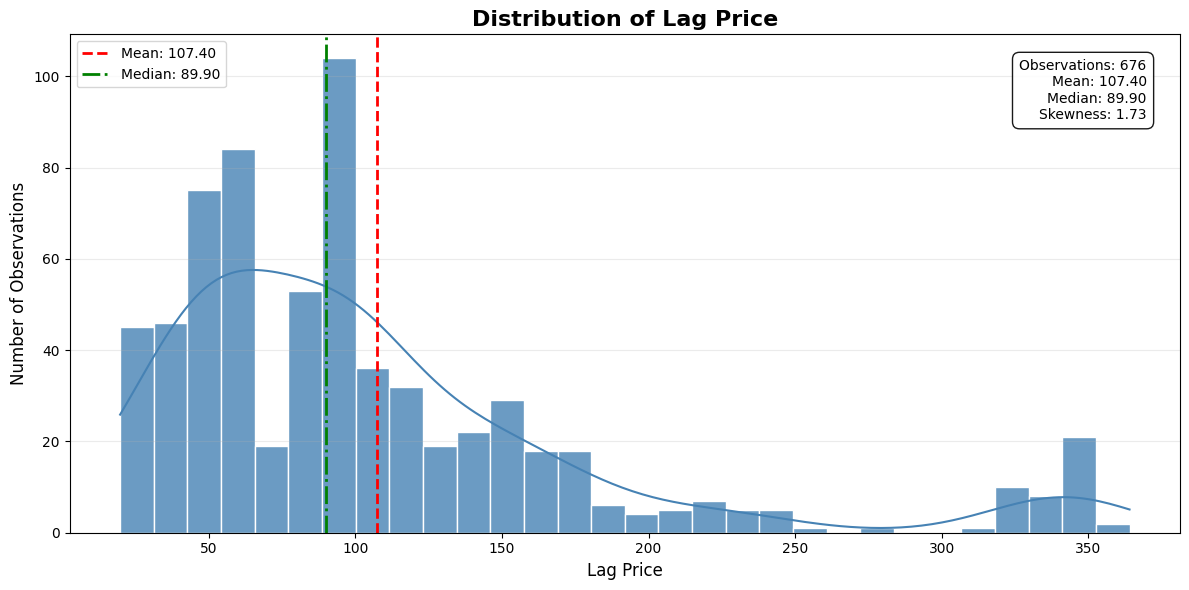

In [16]:
# Visualize the distribution of the target variable

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

target = "lag_price"
data = df[target].dropna()

mean_val = data.mean()
median_val = data.median()
skew_val = data.skew()

plt.figure(figsize=(12, 6))

sns.histplot(
    data,
    bins=30,
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.8
)

plt.axvline(
    mean_val,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_val:.2f}"
)

plt.axvline(
    median_val,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_val:.2f}"
)

plt.title("Distribution of Lag Price", fontsize=16, fontweight="bold")
plt.xlabel("Lag Price", fontsize=12)
plt.ylabel("Number of Observations", fontsize=12)

plt.text(
    0.97, 0.95,
    f"Observations: {len(data)}\n"
    f"Mean: {mean_val:.2f}\n"
    f"Median: {median_val:.2f}\n"
    f"Skewness: {skew_val:.2f}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9)
)

plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

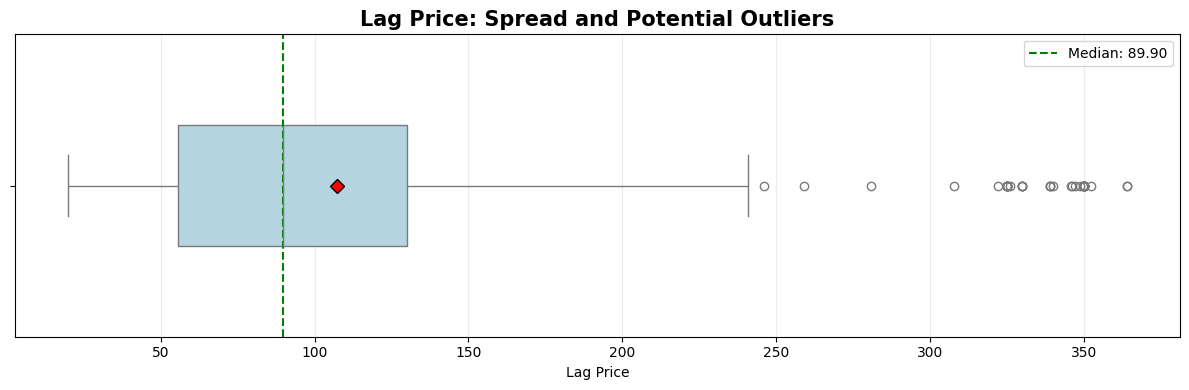

In [17]:
# Visualize the spread and potential outliers of the target variable

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=data,
    color="lightblue",
    width=0.4,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

plt.axvline(
    median_val,
    color="green",
    linestyle="--",
    label=f"Median: {median_val:.2f}"
)

plt.title("Lag Price: Spread and Potential Outliers",
          fontsize=15, fontweight="bold")
plt.xlabel("Lag Price")
plt.grid(axis="x", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Calculate Quartiles and IQR

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = data[(data < lower_bound) | (data > upper_bound)]

print("Number of outliers:", len(outliers))
print("Percentage of outliers:", len(outliers) / len(data) * 100)

Q1: 55.66875
Q3: 129.99
IQR: 74.32125
Lower Bound: -55.813125
Upper Bound: 241.471875
Number of outliers: 45
Percentage of outliers: 6.656804733727811


In [19]:
# Identify and display the outliers

lag_outliers = data[data > upper_bound]

print(lag_outliers.sort_values(ascending=False))

483   364.0000
484   364.0000
482   352.2500
477   349.9000
480   349.9000
469   349.9000
468   349.9000
467   349.9000
471   349.9000
466   349.9000
475   349.9000
474   349.9000
479   349.9000
478   349.9000
481   349.9000
472   349.9000
473   349.9000
470   349.9000
465   349.8500
659   348.8000
661   347.0000
657   346.1580
658   345.7067
660   339.9000
656   339.0000
655   339.0000
654   338.9500
445   330.0000
442   330.0000
443   330.0000
444   330.0000
441   325.8929
438   325.0000
436   325.0000
435   325.0000
437   325.0000
434   325.0000
440   325.0000
439   325.0000
433   324.9500
476   322.1364
662   307.8333
663   280.6667
664   258.9696
665   245.9000
Name: lag_price, dtype: float64


In [20]:
outlier_rows = df[df['lag_price'] > upper_bound]

print(outlier_rows)

    product_id product_category_name  month_year  qty  total_price  \
433    health2         health_beauty  01-08-2017    6   1,950.0000   
434    health2         health_beauty  01-09-2017   11   3,575.0000   
435    health2         health_beauty  01-10-2017    2     650.0000   
436    health2         health_beauty  01-11-2017   12   3,900.0000   
437    health2         health_beauty  01-12-2017    6   1,950.0000   
438    health2         health_beauty  01-01-2018   10   3,250.0000   
439    health2         health_beauty  01-02-2018   23   7,475.0000   
440    health2         health_beauty  01-03-2018   28   9,125.0000   
441    health2         health_beauty  01-04-2018   21   6,930.0000   
442    health2         health_beauty  01-05-2018   19   6,270.0000   
443    health2         health_beauty  01-06-2018   16   5,280.0000   
444    health2         health_beauty  01-07-2018   13   4,290.0000   
445    health2         health_beauty  01-08-2018   28   9,240.0000   
465    health5      

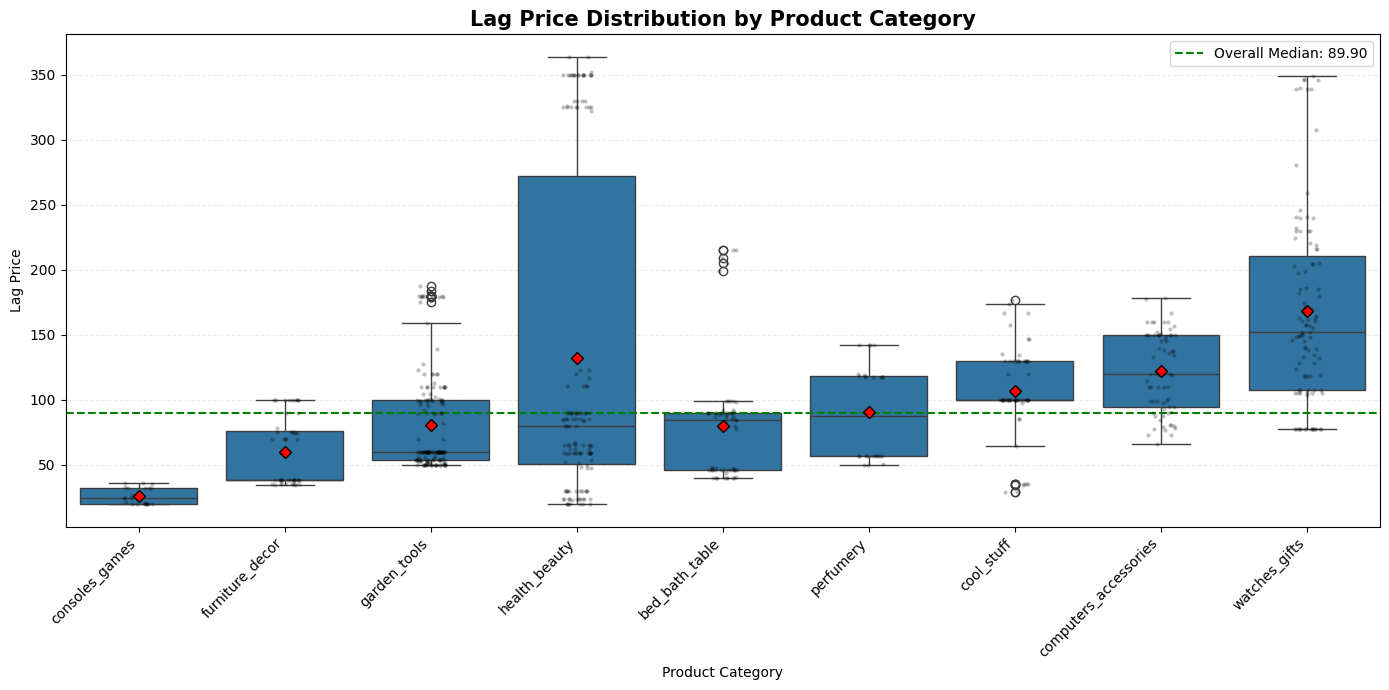

In [21]:
# Analyze the target variable by product category

category_order = (
    df.groupby("product_category_name")[target]
      .median()
      .sort_values()
      .index
)

plt.figure(figsize=(14, 7))

# Boxplot
sns.boxplot(
    data=df,
    x="product_category_name",
    y=target,
    order=category_order,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 6
    }
)

# Individual observations
sns.stripplot(
    data=df,
    x="product_category_name",
    y=target,
    order=category_order,
    color="black",
    alpha=0.25,
    size=3,
    jitter=True
)

# Overall median
plt.axhline(
    df[target].median(),
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Median: {df[target].median():.2f}"
)

plt.title(
    "Lag Price Distribution by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Lag Price")

plt.xticks(rotation=45, ha="right")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# Analyze the target variable by product

product_target = (
    df.groupby("product_id")[target]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("mean", ascending=False)
)

display(product_target.head(20))


,count,mean,median,min,max
product_id,,,,,
health5,20,350.0368,349.9000,322.1364,364.0000
health2,13,326.6033,325.0000,324.9500,330.0000
watches7,12,319.8237,339.0000,245.9000,348.8000
watches5,10,216.9822,217.6238,203.2909,229.9000
bed5,5,208.6920,209.0000,199.5098,215.0000
watches8,10,191.6853,186.0591,145.1667,239.8500
watches1,17,182.0830,182.0000,132.5312,241.0060
garden8,14,175.8420,179.9400,139.0000,187.8543
cool4,9,156.2221,157.3604,134.9400,176.9900


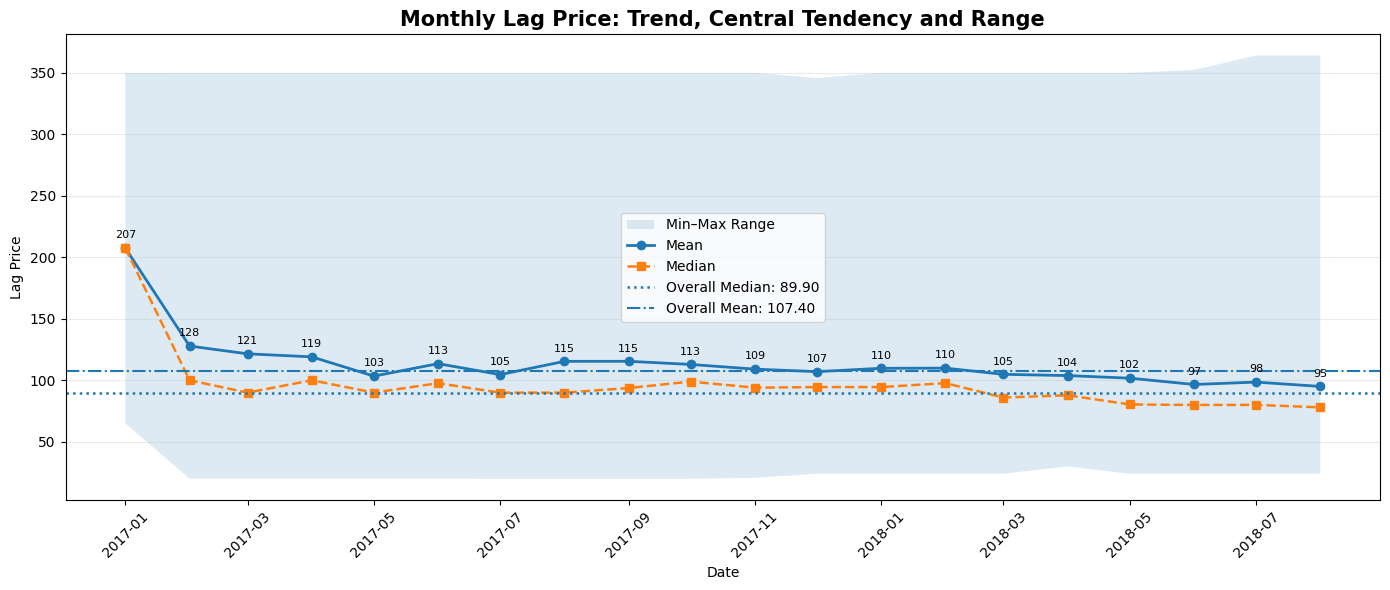

In [23]:
# Visualize the target variable over time

# Make sure date is datetime
df["date"] = pd.to_datetime(df["date"])

# Monthly target statistics
monthly_target = (
    df.groupby(df["date"].dt.to_period("M"))[target]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

monthly_target["date"] = monthly_target["date"].dt.to_timestamp()

# Overall statistics
overall_median = df[target].median()
overall_mean = df[target].mean()

plt.figure(figsize=(14, 6))

# Min-Max range
plt.fill_between(
    monthly_target["date"],
    monthly_target["min"],
    monthly_target["max"],
    alpha=0.15,
    label="Min–Max Range"
)

# Mean
plt.plot(
    monthly_target["date"],
    monthly_target["mean"],
    marker="o",
    linewidth=2,
    label="Mean"
)

# Median
plt.plot(
    monthly_target["date"],
    monthly_target["median"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    label="Median"
)

# Overall median
plt.axhline(
    overall_median,
    linestyle=":",
    linewidth=1.8,
    label=f"Overall Median: {overall_median:.2f}"
)

# Overall mean
plt.axhline(
    overall_mean,
    linestyle="-.",
    linewidth=1.5,
    label=f"Overall Mean: {overall_mean:.2f}"
)

# Annotate mean values
for x, y in zip(monthly_target["date"], monthly_target["mean"]):
    plt.annotate(
        f"{y:.0f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 7),
        ha="center",
        fontsize=8
    )

plt.title(
    "Monthly Lag Price: Trend, Central Tendency and Range",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Lag Price")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.25)

plt.legend()
plt.tight_layout()
plt.show()

# PRICING ANALYSIS
We now examine our current price (unit_price) and how it behaves across products, categories and time.

,unit_price
count,676.0000
mean,106.4968
std,76.1830
min,19.9000
25%,53.9000
50%,89.9000
75%,129.9900
max,364.0000


Missing values: 0
Unique values: 280
Skewness: 1.7787534169905064


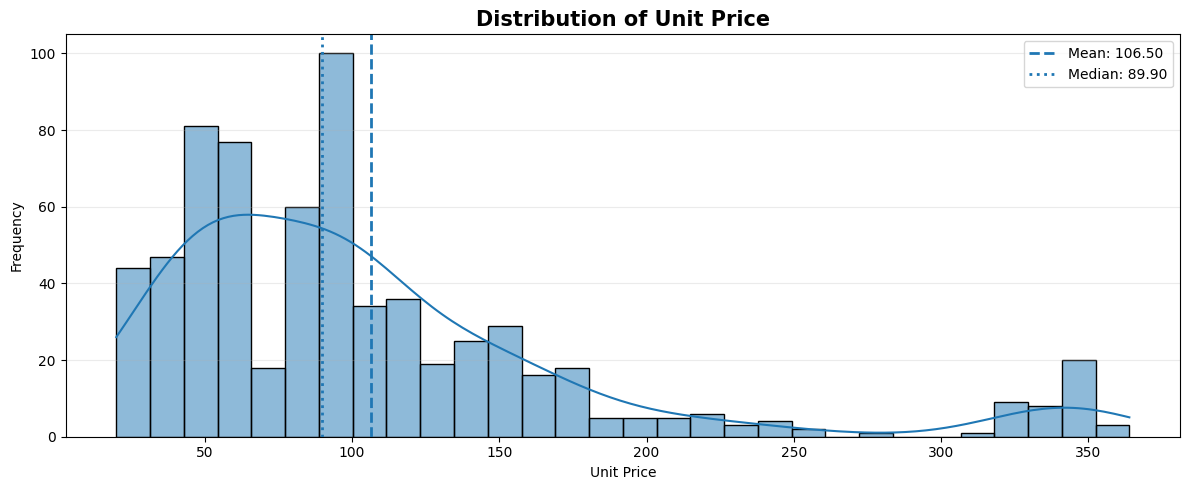

In [24]:
# Unit Price summary statistics

display(df["unit_price"].describe().to_frame("unit_price"))

# Missing values
print("Missing values:", df["unit_price"].isna().sum())

# Unique values
print("Unique values:", df["unit_price"].nunique())

# Skewness
print("Skewness:", df["unit_price"].skew())


# Distribution


plt.figure(figsize=(12, 5))

sns.histplot(
    df["unit_price"],
    kde=True,
    bins=30
)

plt.axvline(
    df["unit_price"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {df['unit_price'].mean():.2f}"
)

plt.axvline(
    df["unit_price"].median(),
    linestyle=":",
    linewidth=2,
    label=f"Median: {df['unit_price'].median():.2f}"
)

plt.title(
    "Distribution of Unit Price",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

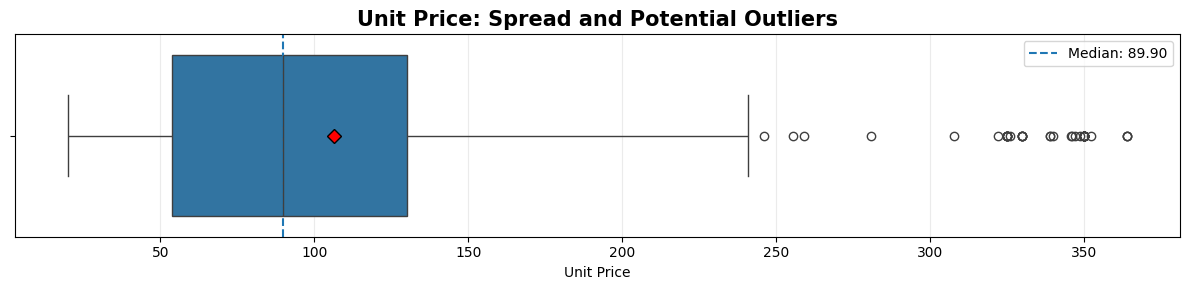

In [25]:
# unit_price spread and potential outliers

plt.figure(figsize=(12, 3))

sns.boxplot(
    x=df["unit_price"],
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

plt.axvline(
    df["unit_price"].median(),
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {df['unit_price'].median():.2f}"
)

plt.title(
    "Unit Price: Spread and Potential Outliers",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unit Price")
plt.grid(axis="x", alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

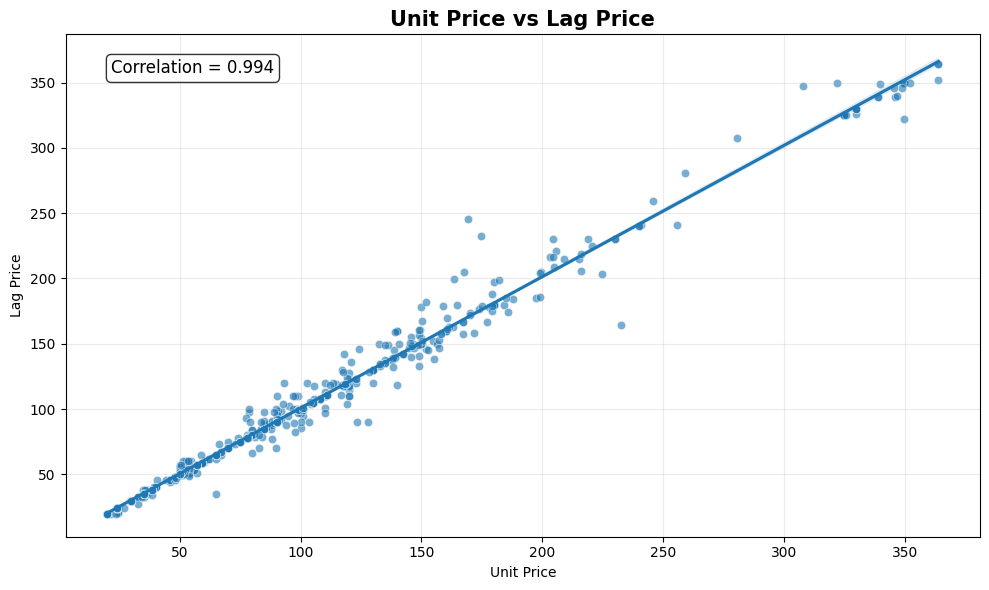

In [26]:
# Correlation between unit_price and lag_price

correlation = df["unit_price"].corr(df[target])

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="unit_price",
    y=target,
    alpha=0.6
)

sns.regplot(
    data=df,
    x="unit_price",
    y=target,
    scatter=False
)

plt.text(
    0.05,
    0.95,
    f"Correlation = {correlation:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

plt.title(
    "Unit Price vs Lag Price",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Unit Price")
plt.ylabel("Lag Price")

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

,count,mean,median,min,max
product_category_name,,,,,
consoles_games,22,27.0338,24.5000,19.9000,36.2000
furniture_decor,48,60.1543,38.4000,34.5812,103.2333
garden_tools,160,80.0947,59.9000,49.9000,187.8543
health_beauty,130,132.3099,79.9900,19.9900,364.0000
bed_bath_table,61,78.6293,84.9000,39.2400,215.0000
perfumery,26,89.3488,86.9483,49.9900,142.5000
cool_stuff,57,107.8575,99.9900,29.5000,176.9900
computers_accessories,69,119.4823,119.9900,66.3421,178.0571
watches_gifts,103,164.8800,150.1333,77.8214,348.8000


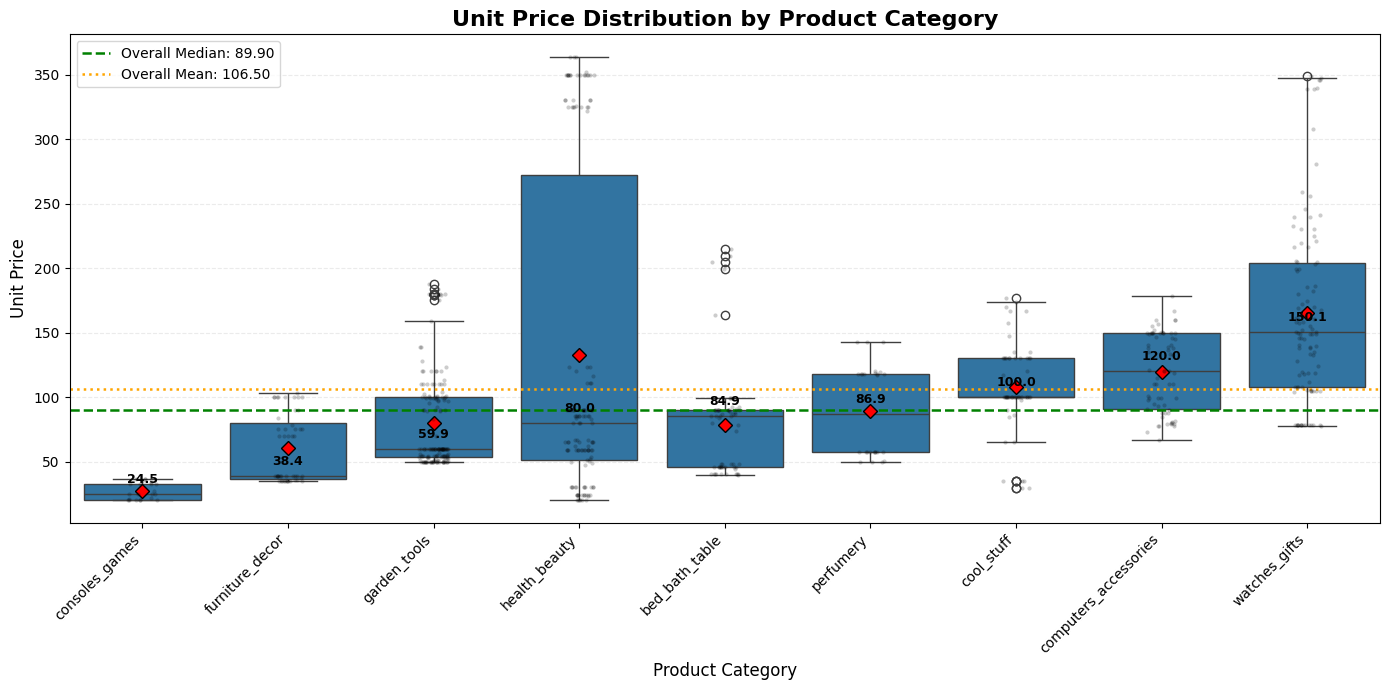

In [27]:
# unit_price by product category

# Category summary
category_unit_price = (
    df.groupby("product_category_name")["unit_price"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("median", ascending=True)
)

display(category_unit_price)


category_order = category_unit_price.index.tolist()

overall_median = df["unit_price"].median()
overall_mean = df["unit_price"].mean()



plt.figure(figsize=(14, 7))

# Boxplot
sns.boxplot(
    data=df,
    x="product_category_name",
    y="unit_price",
    order=category_order,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

# Individual observations
sns.stripplot(
    data=df,
    x="product_category_name",
    y="unit_price",
    order=category_order,
    color="black",
    alpha=0.20,
    size=3,
    jitter=True
)

# Overall median
plt.axhline(
    overall_median,
    color="green",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Median: {overall_median:.2f}"
)

# Overall mean
plt.axhline(
    overall_mean,
    color="orange",
    linestyle=":",
    linewidth=1.8,
    label=f"Overall Mean: {overall_mean:.2f}"
)



# Add median labels


for i, category in enumerate(category_order):

    median_value = category_unit_price.loc[
        category, "median"
    ]

    plt.annotate(
        f"{median_value:.1f}",
        xy=(i, median_value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )



# Formatting


plt.title(
    "Unit Price Distribution by Product Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Product Category",
    fontsize=12
)

plt.ylabel(
    "Unit Price",
    fontsize=12
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

plt.legend()

plt.tight_layout()
plt.show()

# SALES / DEMAND ANALYSIS

In [28]:
# Sales summary statistics

sales_cols = ["qty", "customers", "total_price"]


sales_summary = (
    df[sales_cols]
    .describe()
    .T
)

# Add additional statistics
sales_summary["median"] = df[sales_cols].median()
sales_summary["skewness"] = df[sales_cols].skew()
sales_summary["missing"] = df[sales_cols].isna().sum()
sales_summary["unique"] = df[sales_cols].nunique()

display(sales_summary)

,count,mean,std,min,25%,50%,75%,max,median,skewness,missing,unique
qty,676.0000,14.4956,15.4434,1.0000,4.0000,10.0000,18.0000,122.0000,10.0000,2.6735,0,66
customers,676.0000,81.0281,62.0556,1.0000,34.0000,62.0000,116.0000,339.0000,62.0000,1.4027,0,94
total_price,676.0000,"1,422.7087","1,700.1231",19.9000,333.7000,807.8900,"1,887.3225","12,095.0000",807.8900,2.6140,0,573


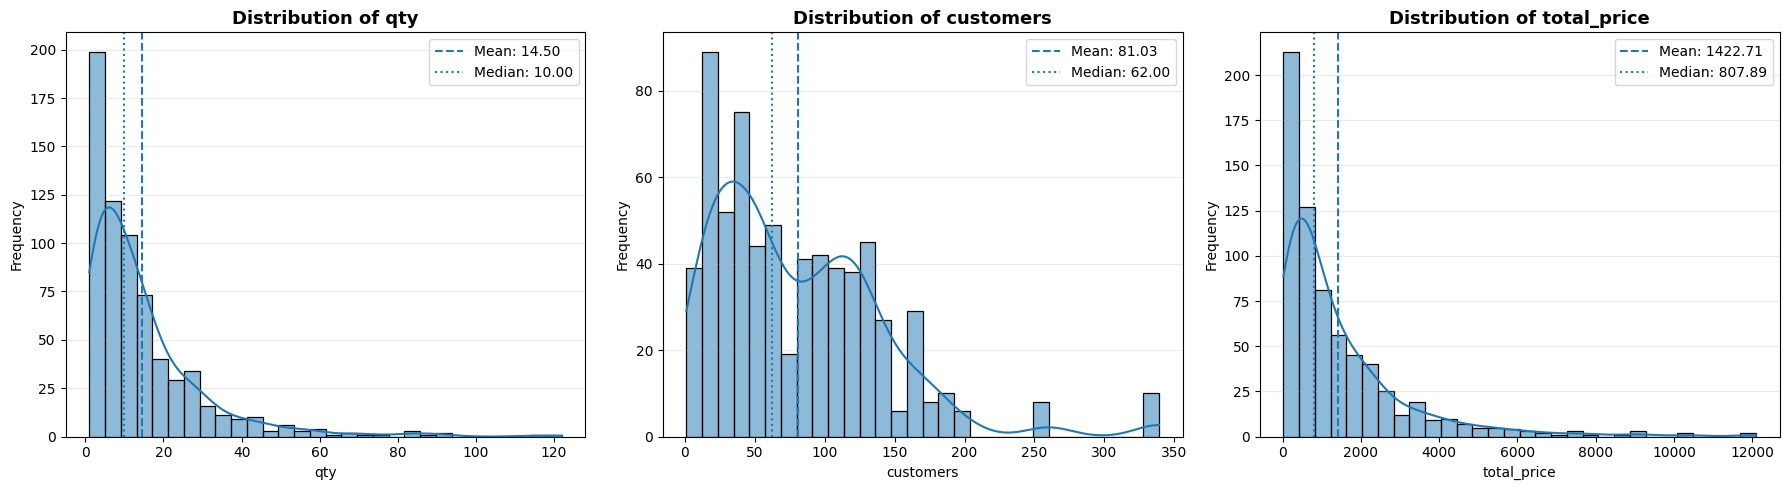

In [29]:
# Visualize the distribution of sales-related variables

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, sales_cols):

    sns.histplot(
        df[col].dropna(),
        kde=True,
        bins=30,
        ax=ax
    )

    ax.axvline(
        df[col].mean(),
        linestyle="--",
        linewidth=1.5,
        label=f"Mean: {df[col].mean():.2f}"
    )

    ax.axvline(
        df[col].median(),
        linestyle=":",
        linewidth=1.5,
        label=f"Median: {df[col].median():.2f}"
    )

    ax.set_title(
        f"Distribution of {col}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

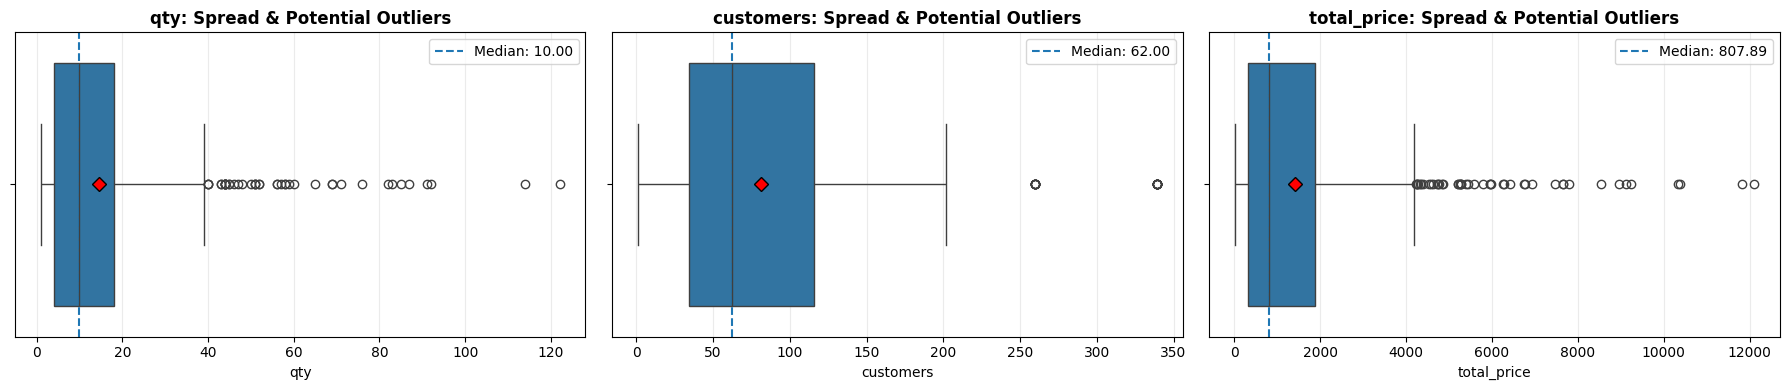

In [30]:
# Visualize the spread and potential outliers of sales-related variables

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, col in zip(axes, sales_cols):

    sns.boxplot(
        x=df[col],
        ax=ax,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "markersize": 7
        }
    )

    ax.axvline(
        df[col].median(),
        linestyle="--",
        linewidth=1.5,
        label=f"Median: {df[col].median():.2f}"
    )

    ax.set_title(
        f"{col}: Spread & Potential Outliers",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(col)
    ax.grid(axis="x", alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

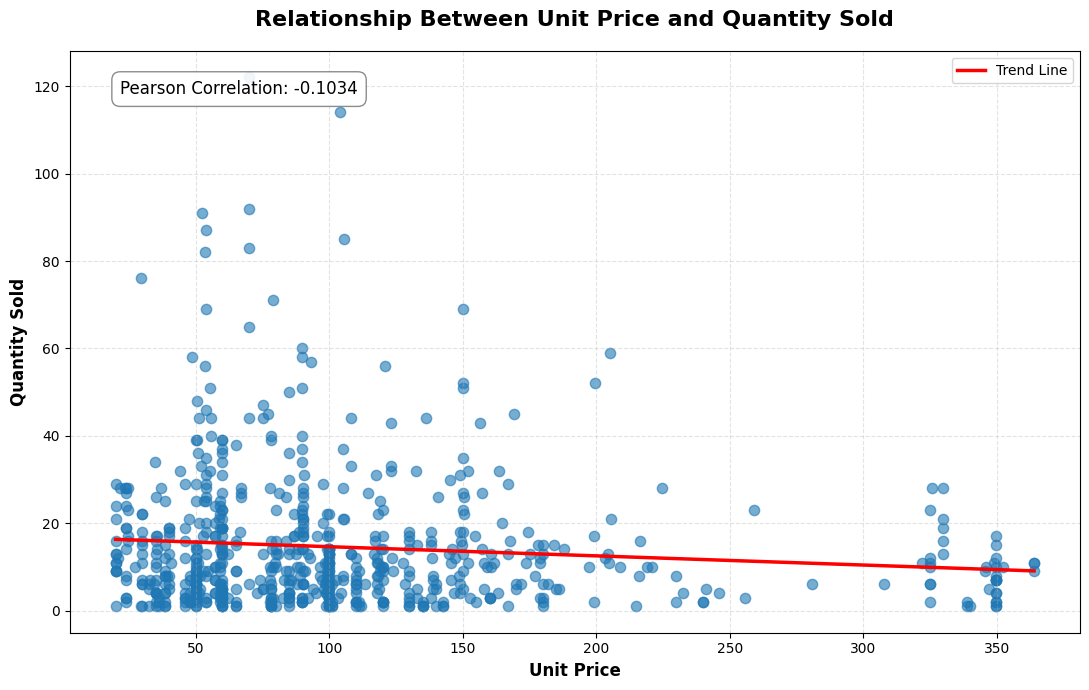

PRICE VS QUANTITY ANALYSIS
Pearson Correlation: -0.1034


In [31]:
# Price vs Quantity Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation
correlation = df["unit_price"].corr(df["qty"])

plt.figure(figsize=(11, 7))

# Scatter plot with trend line
sns.regplot(
    data=df,
    x="unit_price",
    y="qty",
    scatter_kws={
        "alpha": 0.6,
        "s": 55
    },
    line_kws={
        "color": "red",
        "linewidth": 2.5,
        "label": "Trend Line"
    },
    ci=None
)

# Title and axis labels
plt.title(
    "Relationship Between Unit Price and Quantity Sold",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Unit Price", fontsize=12, fontweight="bold")
plt.ylabel("Quantity Sold", fontsize=12, fontweight="bold")

# Correlation annotation
plt.text(
    0.05, 0.95,
    f"Pearson Correlation: {correlation:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

# Grid, legend, and layout
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# Print result
print("=" * 50)
print("PRICE VS QUANTITY ANALYSIS")
print("=" * 50)
print(f"Pearson Correlation: {correlation:.4f}")


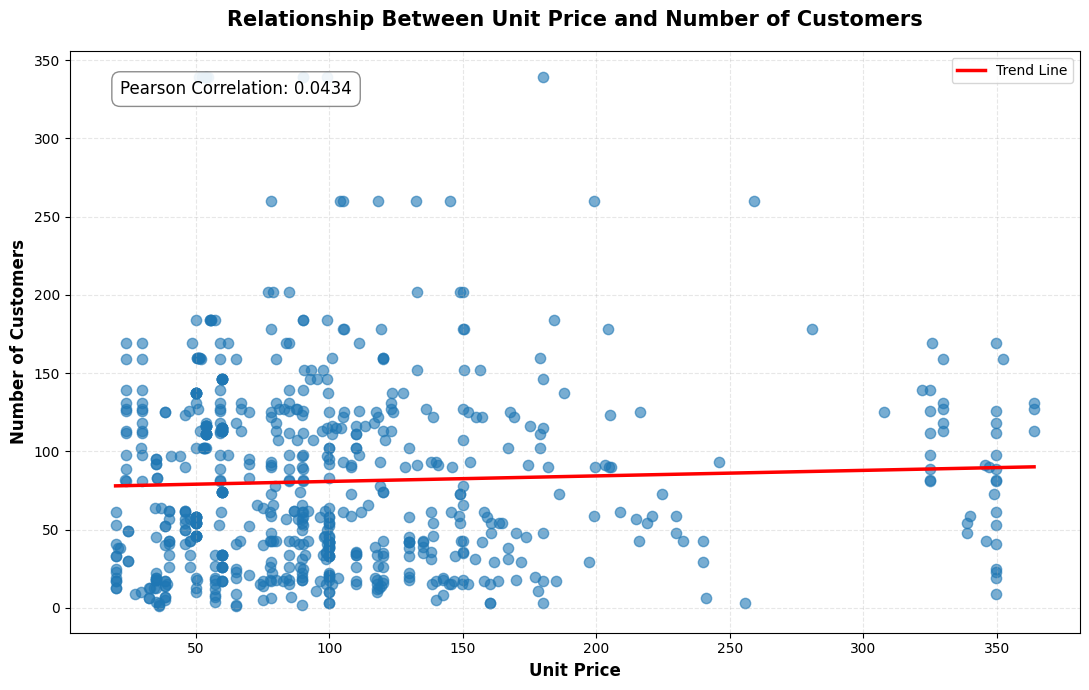

PRICE VS CUSTOMERS ANALYSIS
Pearson Correlation: 0.0434
Interpretation: Weak positive linear relationship.


In [32]:
# unit_price vs customers analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation
correlation = df["unit_price"].corr(df["customers"])

# Create plot
plt.figure(figsize=(11, 7))

sns.regplot(
    data=df,
    x="unit_price",
    y="customers",
    scatter_kws={
        "alpha": 0.6,
        "s": 55
    },
    line_kws={
        "color": "red",
        "linewidth": 2.5,
        "label": "Trend Line"
    },
    ci=None
)

# Title and axis labels
plt.title(
    "Relationship Between Unit Price and Number of Customers",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Unit Price", fontsize=12, fontweight="bold")
plt.ylabel("Number of Customers", fontsize=12, fontweight="bold")

# Display correlation on plot
plt.text(
    0.05, 0.95,
    f"Pearson Correlation: {correlation:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

# Formatting
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# Print analysis
print("=" * 55)
print("PRICE VS CUSTOMERS ANALYSIS")
print("=" * 55)
print(f"Pearson Correlation: {correlation:.4f}")

if correlation < -0.5:
    print("Interpretation: Strong negative linear relationship.")
elif correlation < -0.3:
    print("Interpretation: Moderate negative linear relationship.")
elif correlation < 0:
    print("Interpretation: Weak negative linear relationship.")
elif correlation < 0.3:
    print("Interpretation: Weak positive linear relationship.")
elif correlation < 0.5:
    print("Interpretation: Moderate positive linear relationship.")
else:
    print("Interpretation: Strong positive linear relationship.")


,date,total_sales,total_qty,customers,avg_price
0,2017-01-01,"2,864.1900",9,18,207.4450
1,2017-02-01,"3,584.1100",35,78,127.8271
2,2017-03-01,"10,204.3800",101,242,122.5866
3,2017-04-01,"11,524.6200",121,309,119.2887
4,2017-05-01,"21,843.3300",222,803,104.7858
5,2017-06-01,"23,245.2400",233,820,112.1521
6,2017-07-01,"41,049.8900",403,1686,105.1119
7,2017-08-01,"49,550.4100",495,2279,114.7373
8,2017-09-01,"44,826.6000",450,2275,112.3363
9,2017-10-01,"48,569.3800",550,2949,113.6235


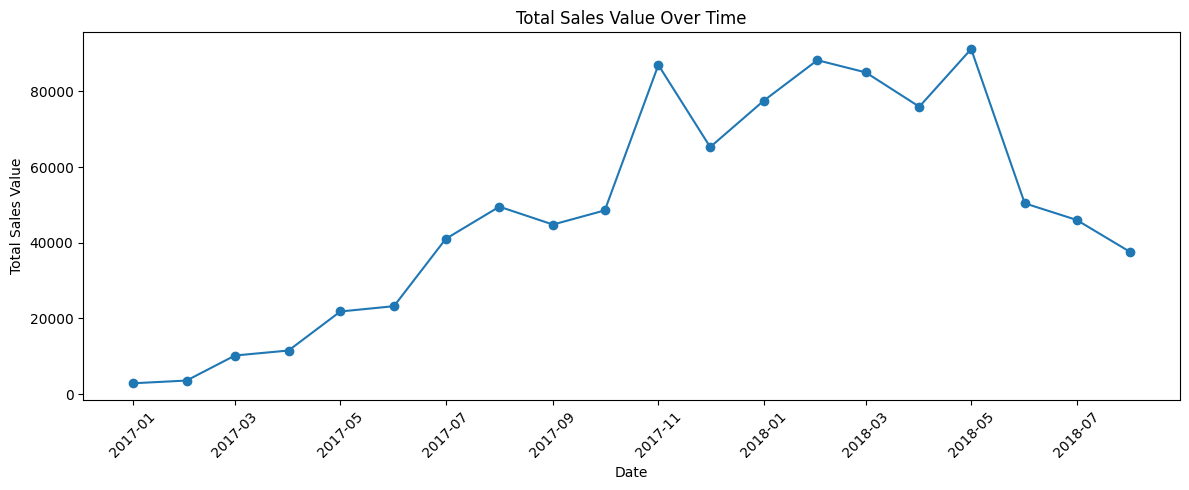

In [33]:

# ============================================================
# 11.4 TOTAL SALES OVER TIME
# ============================================================

monthly_sales = (
    df.groupby("date")
      .agg(
          total_sales=("total_price", "sum"),
          total_qty=("qty", "sum"),
          customers=("customers", "sum"),
          avg_price=("unit_price", "mean")
      )
      .reset_index()
)

display(monthly_sales)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["date"], monthly_sales["total_sales"], marker="o")
plt.title("Total Sales Value Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,date,total_sales,total_qty,customers,avg_price
0,2017-01-01,"2,864.1900",9,18,207.4450
1,2017-02-01,"3,584.1100",35,78,127.8271
2,2017-03-01,"10,204.3800",101,242,122.5866
3,2017-04-01,"11,524.6200",121,309,119.2887
4,2017-05-01,"21,843.3300",222,803,104.7858
5,2017-06-01,"23,245.2400",233,820,112.1521
6,2017-07-01,"41,049.8900",403,1686,105.1119
7,2017-08-01,"49,550.4100",495,2279,114.7373
8,2017-09-01,"44,826.6000",450,2275,112.3363
9,2017-10-01,"48,569.3800",550,2949,113.6235


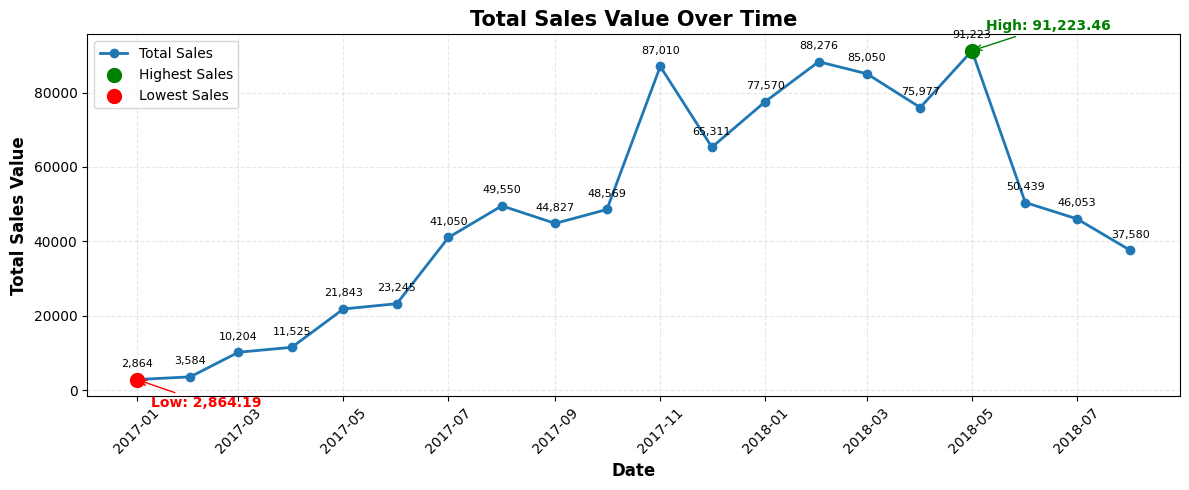

Highest Sales: 91,223.46 on 2018-05-01 00:00:00
Lowest Sales : 2,864.19 on 2017-01-01 00:00:00


In [34]:
# total sales over time 

monthly_sales = (
    df.groupby("date")
      .agg(
          total_sales=("total_price", "sum"),
          total_qty=("qty", "sum"),
          customers=("customers", "sum"),
          avg_price=("unit_price", "mean")
      )
      .reset_index()
      .sort_values("date")
)

display(monthly_sales)

# Find highest and lowest sales
max_idx = monthly_sales["total_sales"].idxmax()
min_idx = monthly_sales["total_sales"].idxmin()

highest = monthly_sales.loc[max_idx]
lowest = monthly_sales.loc[min_idx]

# Original plot with added labels
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["date"],
    monthly_sales["total_sales"],
    marker="o",
    markersize=6,
    linewidth=2,
    label="Total Sales"
)

# Label each data point with its value
for _, row in monthly_sales.iterrows():
    plt.annotate(
        f'{row["total_sales"]:,.0f}',
        (row["date"], row["total_sales"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=8
    )

# Highlight highest sales
plt.scatter(
    highest["date"], highest["total_sales"],
    color="green", s=100, zorder=5,
    label="Highest Sales"
)

plt.annotate(
    f'High: {highest["total_sales"]:,.2f}',
    (highest["date"], highest["total_sales"]),
    textcoords="offset points",
    xytext=(10, 15),
    ha="left",
    color="green",
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="green")
)

# Highlight lowest sales
plt.scatter(
    lowest["date"], lowest["total_sales"],
    color="red", s=100, zorder=5,
    label="Lowest Sales"
)

plt.annotate(
    f'Low: {lowest["total_sales"]:,.2f}',
    (lowest["date"], lowest["total_sales"]),
    textcoords="offset points",
    xytext=(10, -20),
    ha="left",
    color="red",
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="red")
)

# Titles and labels
plt.title(
    "Total Sales Value Over Time",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales Value", fontsize=12, fontweight="bold")

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Print high and low values
print(f"Highest Sales: {highest['total_sales']:,.2f} on {highest['date']}")
print(f"Lowest Sales : {lowest['total_sales']:,.2f} on {lowest['date']}")


# COMPETITOR ANALYSIS
We compare our product price against:
- comp_1
- comp_2
- comp_3
and later compare competitor ratings and freight prices.

The purpose is to understand competitive positioning.

,count,mean,std,min,25%,50%,75%,max,missing_values,missing_pct
unit_price,676.0000,106.5000,76.1800,19.9000,53.9000,89.9000,129.9900,364.0000,0,0.0000
comp_1,676.0000,79.4500,47.9300,19.9000,49.9100,69.9000,104.2600,349.9000,0,0.0000
comp_2,676.0000,92.9300,49.4800,19.9000,53.9000,89.9900,117.8900,349.9000,0,0.0000
comp_3,676.0000,84.1800,47.7500,19.9000,53.7900,59.9000,99.9900,255.6100,0,0.0000


,price_source,mean,min,max
0,Our Price,106.5000,19.9000,364.0000
1,Competitor 1,79.4500,19.9000,349.9000
2,Competitor 2,92.9300,19.9000,349.9000
3,Competitor 3,84.1800,19.9000,255.6100


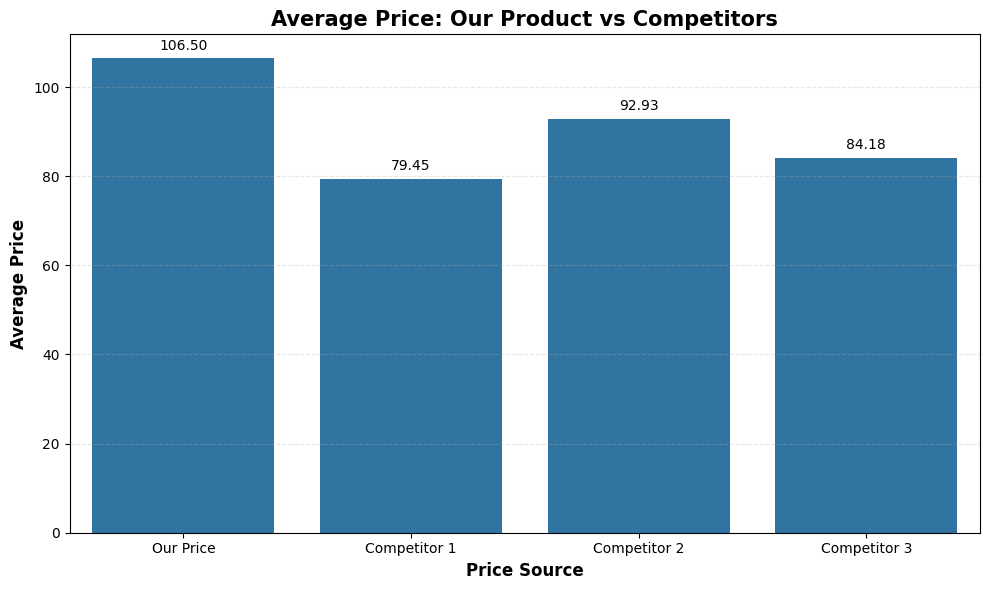

COMPETITOR PRICE SUMMARY

unit_price:
  Average Price : 106.50
  Lowest Price  : 19.90
  Highest Price : 364.00
  Missing Values: 0

comp_1:
  Average Price : 79.45
  Lowest Price  : 19.90
  Highest Price : 349.90
  Missing Values: 0

comp_2:
  Average Price : 92.93
  Lowest Price  : 19.90
  Highest Price : 349.90
  Missing Values: 0

comp_3:
  Average Price : 84.18
  Lowest Price  : 19.90
  Highest Price : 255.61
  Missing Values: 0


In [35]:
# competitor price analysis

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

competitor_cols = ["unit_price", "comp_1", "comp_2", "comp_3"]

# Descriptive statistics
price_summary = df[competitor_cols].describe().T

# Add missing values and missing percentage
price_summary["missing_values"] = df[competitor_cols].isnull().sum()
price_summary["missing_pct"] = (
    df[competitor_cols].isnull().mean() * 100
)

# Display formatted summary
display(price_summary.round(2))

# ============================================================
# VISUAL COMPARISON OF COMPETITOR PRICES
# ============================================================

comparison = (
    df[competitor_cols]
    .agg(["mean", "min", "max"])
    .T
    .reset_index()
    .rename(columns={"index": "price_source"})
)

comparison["price_source"] = comparison["price_source"].replace({
    "unit_price": "Our Price",
    "comp_1": "Competitor 1",
    "comp_2": "Competitor 2",
    "comp_3": "Competitor 3"
})

display(comparison.round(2))

# Plot average prices
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=comparison,
    x="price_source",
    y="mean"
)

# Add average price labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

plt.title(
    "Average Price: Our Product vs Competitors",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Price Source", fontsize=12, fontweight="bold")
plt.ylabel("Average Price", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# HIGHEST AND LOWEST PRICES
# ============================================================

print("=" * 55)
print("COMPETITOR PRICE SUMMARY")
print("=" * 55)

for col in competitor_cols:
    print(f"\n{col}:")
    print(f"  Average Price : {df[col].mean():,.2f}")
    print(f"  Lowest Price  : {df[col].min():,.2f}")
    print(f"  Highest Price : {df[col].max():,.2f}")
    print(f"  Missing Values: {df[col].isna().sum()}")


,count,mean,std,min,25%,50%,75%,max,median
gap_comp_1,676.0000,27.0400,76.0600,-85.0000,0.0000,0.0000,39.1400,340.0100,0.0000
gap_comp_2,676.0000,13.5700,68.8100,-169.0500,-0.0600,0.0000,13.5200,284.0100,0.0000
gap_comp_3,676.0000,22.3100,72.7400,-163.0100,0.0000,0.0000,34.9100,305.0100,0.0000


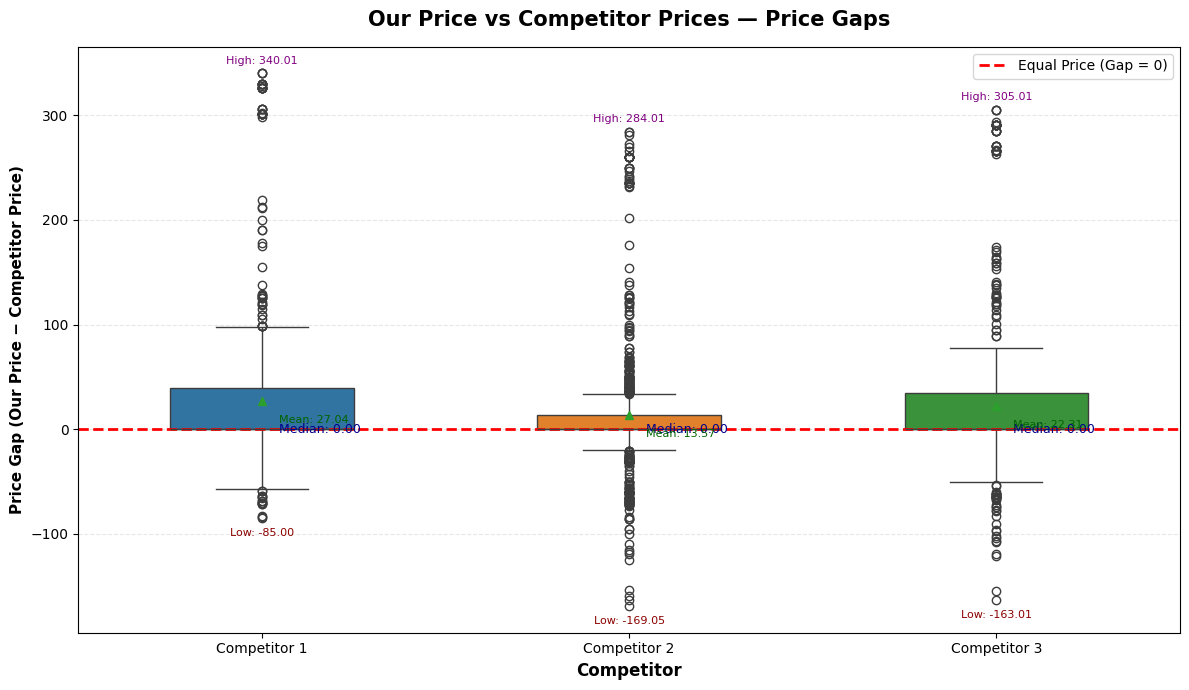

In [36]:
# compitators price gap analysis

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate price gaps and ratios
for c in ["comp_1", "comp_2", "comp_3"]:
    df[f"gap_{c}"] = df["unit_price"] - df[c]
    df[f"ratio_{c}"] = (
        df["unit_price"] / df[c].replace(0, np.nan)
    )

gap_cols = ["gap_comp_1", "gap_comp_2", "gap_comp_3"]

# Summary statistics
gap_summary = df[gap_cols].describe().T
gap_summary["median"] = df[gap_cols].median()
display(gap_summary.round(2))

# Plot
plt.figure(figsize=(12, 7))
ax = sns.boxplot(data=df[gap_cols], width=0.5, showmeans=True)

# Zero line: our price equals competitor price
ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Equal Price (Gap = 0)"
)

# Add median, mean, minimum and maximum labels
for i, col in enumerate(gap_cols):
    values = df[col].dropna()

    if values.empty:
        continue

    median_val = values.median()
    mean_val = values.mean()
    min_val = values.min()
    max_val = values.max()

    # Median label
    ax.annotate(
        f"Median: {median_val:,.2f}",
        xy=(i, median_val),
        xytext=(12, 0),
        textcoords="offset points",
        fontsize=9,
        color="darkblue",
        va="center"
    )

    # Mean label
    ax.annotate(
        f"Mean: {mean_val:,.2f}",
        xy=(i, mean_val),
        xytext=(12, -14),
        textcoords="offset points",
        fontsize=8,
        color="darkgreen",
        va="center"
    )

    # High and low values
    ax.annotate(
        f"High: {max_val:,.2f}",
        xy=(i, max_val),
        xytext=(0, 7),
        textcoords="offset points",
        fontsize=8,
        color="purple",
        ha="center"
    )

    ax.annotate(
        f"Low: {min_val:,.2f}",
        xy=(i, min_val),
        xytext=(0, -13),
        textcoords="offset points",
        fontsize=8,
        color="darkred",
        ha="center"
    )

# Clear labels
ax.set_xticks(range(len(gap_cols)))
ax.set_xticklabels(["Competitor 1", "Competitor 2", "Competitor 3"])

plt.title(
    "Our Price vs Competitor Prices — Price Gaps",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("Competitor", fontsize=12, fontweight="bold")
plt.ylabel("Price Gap (Our Price − Competitor Price)",
           fontsize=11, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()



comp_1
Our price above competitor: 293 (43.3%)
Our price below competitor: 138 (20.4%)
Our price equal to competitor: 245 (36.2%)

comp_2
Our price above competitor: 190 (28.1%)
Our price below competitor: 169 (25.0%)
Our price equal to competitor: 317 (46.9%)

comp_3
Our price above competitor: 255 (37.7%)
Our price below competitor: 134 (19.8%)
Our price equal to competitor: 287 (42.5%)


,Competitor,Above,Below,Equal,Total
0,Comp 1,293,138,245,676
1,Comp 2,190,169,317,676
2,Comp 3,255,134,287,676


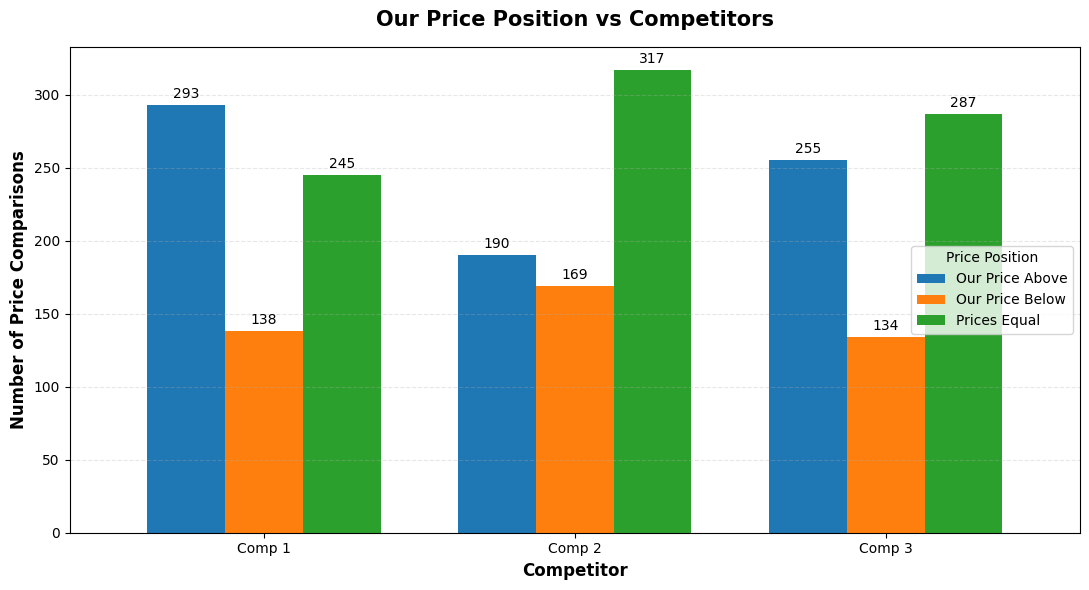

In [37]:
# HOW OFTEN ARE WE ABOVE / BELOW COMPETITORS?

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

competitors = ["comp_1", "comp_2", "comp_3"]
results = []

for c in competitors:
    valid = df[["unit_price", c]].dropna()

    above = (valid["unit_price"] > valid[c]).sum()
    below = (valid["unit_price"] < valid[c]).sum()
    equal = (valid["unit_price"] == valid[c]).sum()
    total = len(valid)

    print(f"\n{c}")
    print(f"Our price above competitor: {above} ({above/total*100:.1f}%)" if total else "No valid comparisons")
    print(f"Our price below competitor: {below} ({below/total*100:.1f}%)" if total else "")
    print(f"Our price equal to competitor: {equal} ({equal/total*100:.1f}%)" if total else "")

    results.append({
        "Competitor": c.replace("_", " ").title(),
        "Above": above,
        "Below": below,
        "Equal": equal,
        "Total": total
    })

# Create summary table
comparison = pd.DataFrame(results)
display(comparison)

# ============================================================
# PLOT: PRICE POSITION AGAINST COMPETITORS
# ============================================================

plot_data = comparison.set_index("Competitor")[["Above", "Below", "Equal"]]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=10)

ax.set_title(
    "Our Price Position vs Competitors",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Competitor", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of Price Comparisons", fontsize=12, fontweight="bold")

ax.set_xticklabels(plot_data.index, rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(
    title="Price Position",
    labels=["Our Price Above", "Our Price Below", "Prices Equal"]
)

plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
product_score,676.0000,4.0900,0.2300,3.3000,3.9000,4.1000,4.2000,4.5000
ps1,676.0000,4.1600,0.1200,3.7000,4.1000,4.2000,4.2000,4.5000
ps2,676.0000,4.1200,0.2100,3.3000,4.1000,4.2000,4.2000,4.4000
ps3,676.0000,4.0000,0.2300,3.5000,3.9000,4.0000,4.1000,4.4000


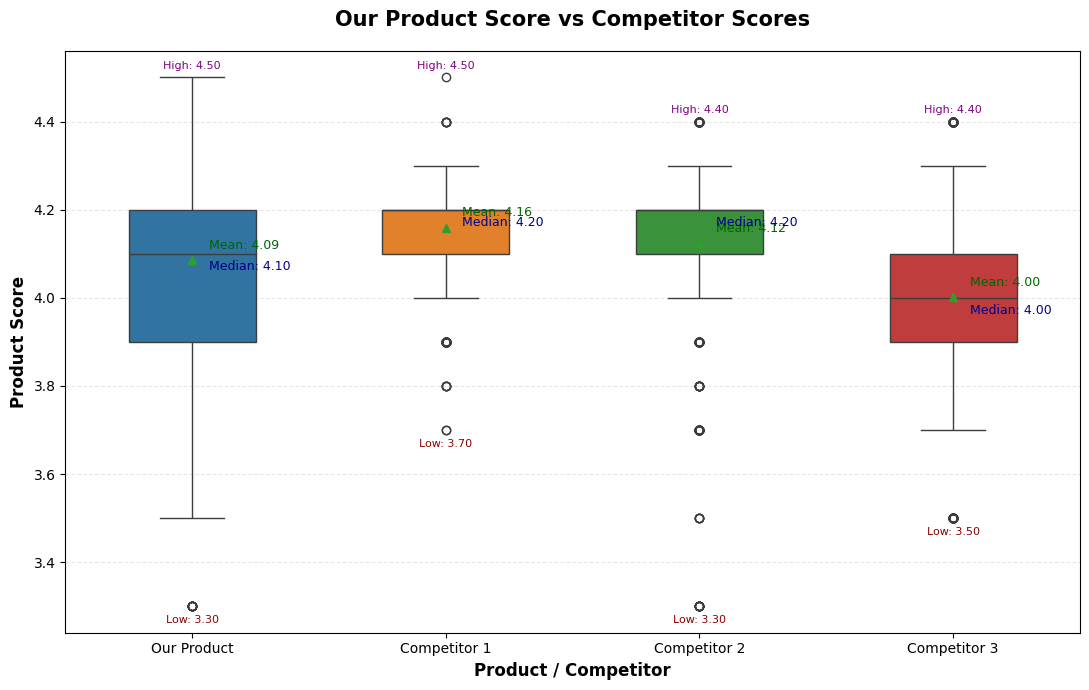

In [38]:
# COMPETITOR RATINGS


rating_cols = ["product_score", "ps1", "ps2", "ps3"]

# Descriptive statistics
display(df[rating_cols].describe().T.round(2))

# Create boxplot
plt.figure(figsize=(11, 7))

ax = sns.boxplot(
    data=df[rating_cols],
    width=0.5,
    showmeans=True
)

# Add mean and median labels
for i, col in enumerate(rating_cols):
    values = df[col].dropna()

    if values.empty:
        continue

    mean_val = values.mean()
    median_val = values.median()
    min_val = values.min()
    max_val = values.max()

    # Mean label
    ax.annotate(
        f"Mean: {mean_val:.2f}",
        xy=(i, mean_val),
        xytext=(12, 8),
        textcoords="offset points",
        fontsize=9,
        color="darkgreen"
    )

    # Median label
    ax.annotate(
        f"Median: {median_val:.2f}",
        xy=(i, median_val),
        xytext=(12, -12),
        textcoords="offset points",
        fontsize=9,
        color="darkblue"
    )

    # Maximum and minimum labels
    ax.annotate(
        f"High: {max_val:.2f}",
        xy=(i, max_val),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="purple"
    )

    ax.annotate(
        f"Low: {min_val:.2f}",
        xy=(i, min_val),
        xytext=(0, -12),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="darkred"
    )

# Titles and axis labels
ax.set_title(
    "Our Product Score vs Competitor Scores",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Product / Competitor", fontsize=12, fontweight="bold")
ax.set_ylabel("Product Score", fontsize=12, fontweight="bold")

ax.set_xticks(range(len(rating_cols)))
ax.set_xticklabels([
    "Our Product",
    "Competitor 1",
    "Competitor 2",
    "Competitor 3"
])

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
freight_price,676.0000,20.6800,10.0800,0.0000,14.7600,17.5200,22.7100,79.7600
fp1,676.0000,18.6000,9.4100,0.1000,13.8300,16.6200,19.7300,57.2300
fp2,676.0000,18.6200,6.4200,4.4100,14.4800,16.8100,21.6700,57.2300
fp3,676.0000,17.9700,5.5300,7.6700,15.0400,16.5200,19.4500,57.2300


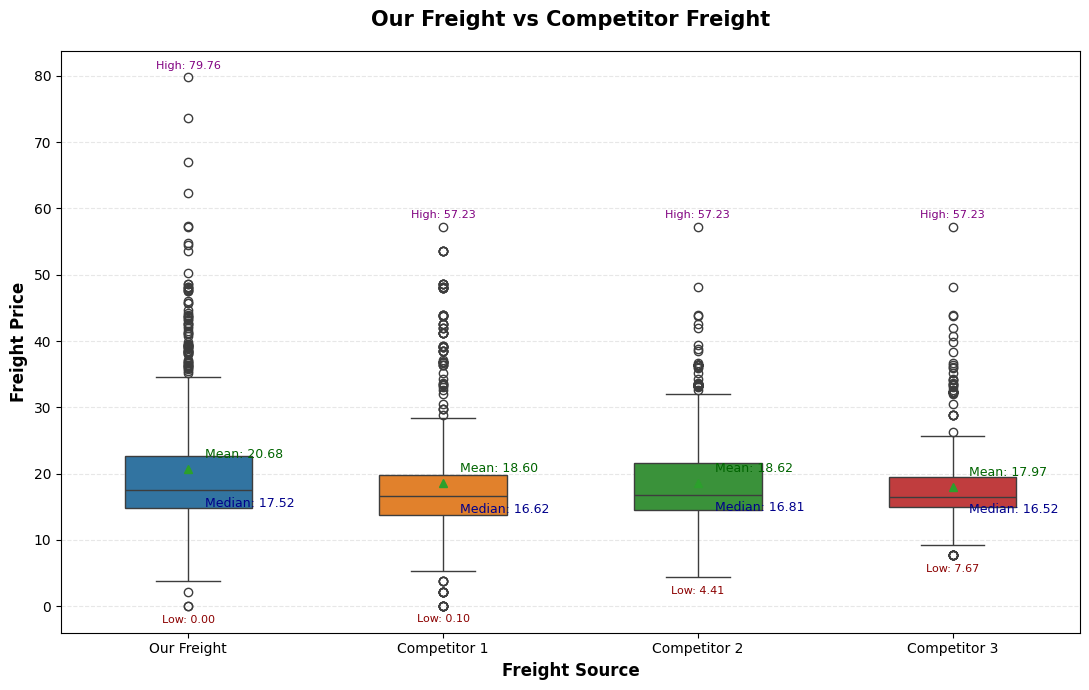

In [39]:
# COMPETITOR FREIGHT

freight_cols = ["freight_price", "fp1", "fp2", "fp3"]

# Summary statistics
display(df[freight_cols].describe().T.round(2))

# Boxplot
plt.figure(figsize=(11, 7))
ax = sns.boxplot(data=df[freight_cols], width=0.5, showmeans=True)

# Add mean, median, high, and low values
for i, col in enumerate(freight_cols):
    values = df[col].dropna()

    if values.empty:
        continue

    mean_val = values.mean()
    median_val = values.median()
    min_val = values.min()
    max_val = values.max()

    ax.annotate(
        f"Mean: {mean_val:.2f}",
        xy=(i, mean_val),
        xytext=(12, 8),
        textcoords="offset points",
        fontsize=9,
        color="darkgreen"
    )

    ax.annotate(
        f"Median: {median_val:.2f}",
        xy=(i, median_val),
        xytext=(12, -12),
        textcoords="offset points",
        fontsize=9,
        color="darkblue"
    )

    ax.annotate(
        f"High: {max_val:.2f}",
        xy=(i, max_val),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="purple"
    )

    ax.annotate(
        f"Low: {min_val:.2f}",
        xy=(i, min_val),
        xytext=(0, -12),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="darkred"
    )

# Titles and labels
ax.set_title(
    "Our Freight vs Competitor Freight",
    fontsize=15,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Freight Source", fontsize=12, fontweight="bold")
ax.set_ylabel("Freight Price", fontsize=12, fontweight="bold")

ax.set_xticks(range(len(freight_cols)))
ax.set_xticklabels([
    "Our Freight",
    "Competitor 1",
    "Competitor 2",
    "Competitor 3"
])

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


# PRODUCT ATTRIBUTE ANALYSIS

In [40]:
# PRODUCT ATTRIBUTES SUMMARY

product_attributes = [
    "product_score",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "volume"
]

display(df[product_attributes].describe().T)


,count,mean,std,min,25%,50%,75%,max
product_score,676.0000,4.0855,0.2320,3.3000,3.9000,4.1000,4.2000,4.5000
product_name_lenght,676.0000,48.7204,9.4207,29.0000,40.0000,51.0000,57.0000,60.0000
product_description_lenght,676.0000,767.3994,655.2050,100.0000,339.0000,501.0000,903.0000,"3,006.0000"
product_photos_qty,676.0000,1.9941,1.4205,1.0000,1.0000,1.5000,2.0000,8.0000
product_weight_g,676.0000,"1,847.4985","2,274.8085",100.0000,348.0000,950.0000,"1,850.0000","9,750.0000"
volume,676.0000,"10,664.6272","9,172.8018",640.0000,"3,510.0000","8,000.0000","15,750.0000","32,736.0000"


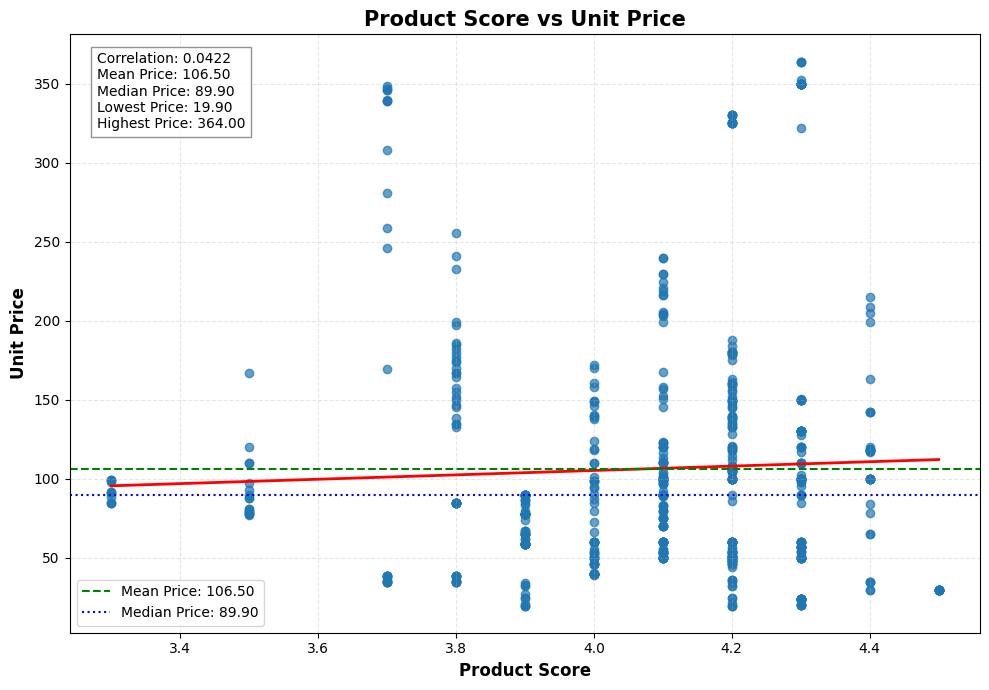

Correlation: 0.0422


In [41]:
# PRODUCT SCORE VS PRICE

plt.figure(figsize=(10, 7))

# Scatterplot with regression line
ax = sns.regplot(
    data=df,
    x="product_score",
    y="unit_price",
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red", "linewidth": 2},
    ci=None
)

# Calculate statistics
correlation = df["product_score"].corr(df["unit_price"])
mean_price = df["unit_price"].mean()
median_price = df["unit_price"].median()
min_price = df["unit_price"].min()
max_price = df["unit_price"].max()

# Mean and median price reference lines
plt.axhline(
    mean_price, color="green", linestyle="--",
    linewidth=1.5, label=f"Mean Price: {mean_price:.2f}"
)
plt.axhline(
    median_price, color="blue", linestyle=":",
    linewidth=1.5, label=f"Median Price: {median_price:.2f}"
)

# Correlation annotation
plt.text(
    0.03, 0.97,
    f"Correlation: {correlation:.4f}\n"
    f"Mean Price: {mean_price:.2f}\n"
    f"Median Price: {median_price:.2f}\n"
    f"Lowest Price: {min_price:.2f}\n"
    f"Highest Price: {max_price:.2f}",
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray")
)

# Titles and labels
plt.title(
    "Product Score vs Unit Price",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Product Score", fontsize=12, fontweight="bold")
plt.ylabel("Unit Price", fontsize=12, fontweight="bold")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation:", round(correlation, 4))


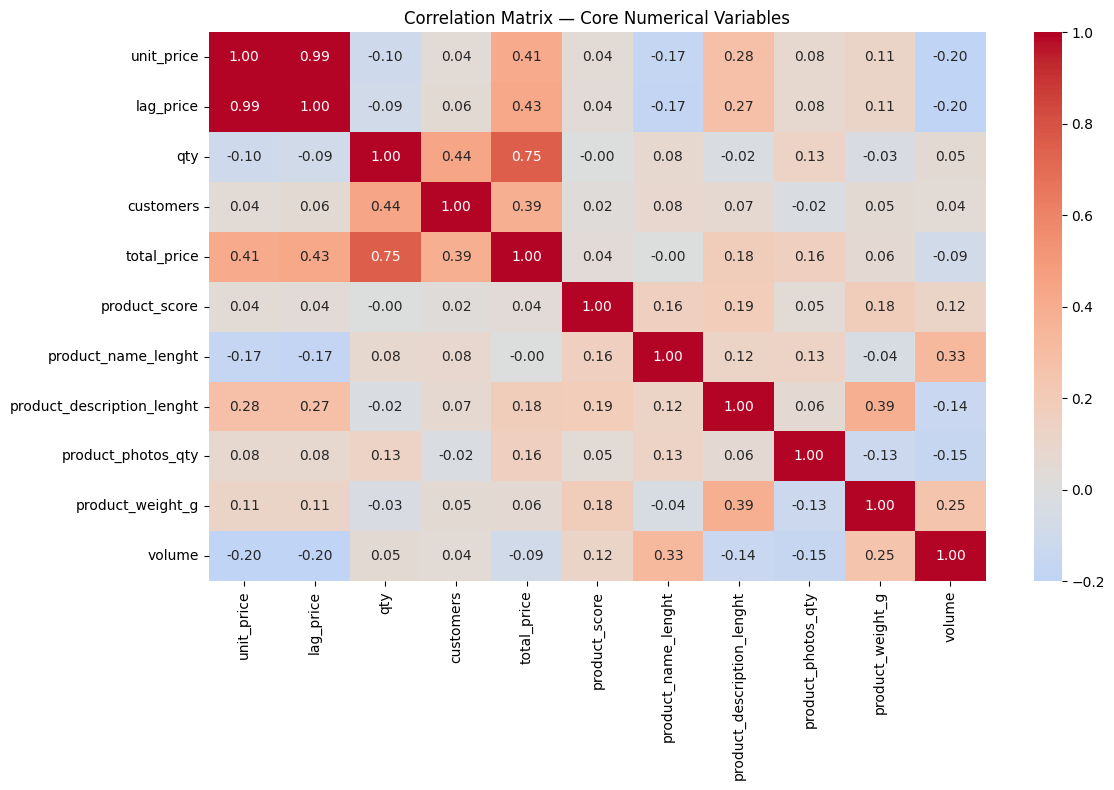

In [42]:
# PRODUCT ATTRIBUTES CORRELATION

attribute_corr_cols = [
    "unit_price", "lag_price", "qty", "customers", "total_price",
    "product_score", "product_name_lenght",
    "product_description_lenght", "product_photos_qty",
    "product_weight_g", "volume"
]

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[attribute_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix — Core Numerical Variables")
plt.tight_layout()
plt.show()


# TIME / SEASONALITY ANALYSIS
We investigate:
- monthly price patterns
- monthly sales patterns
- weekday/weekend/holiday context
- year-to-year movement
- the undocumented s variable

volume is treated as physical product volume, not sales volume.

,month,avg_price,avg_lag_price,avg_qty,total_qty,avg_customers
0,1,113.6000,113.6300,17.5000,875,97.8400
1,2,110.8200,112.6100,15.5900,904,91.6600
2,3,106.1000,108.2500,14.6800,925,87.5900
3,4,105.9400,107.4100,13.9800,881,78.7600
4,5,101.7100,102.2300,18.6700,1120,101.6200
5,6,102.6600,102.8600,10.5500,707,58.1300
6,7,100.1300,101.2400,11.3700,830,61.0300
7,8,104.8500,105.0200,11.0400,828,59.1200
8,9,112.3400,115.3900,12.5000,450,63.1900
9,10,113.6200,112.8500,12.7900,550,68.5800


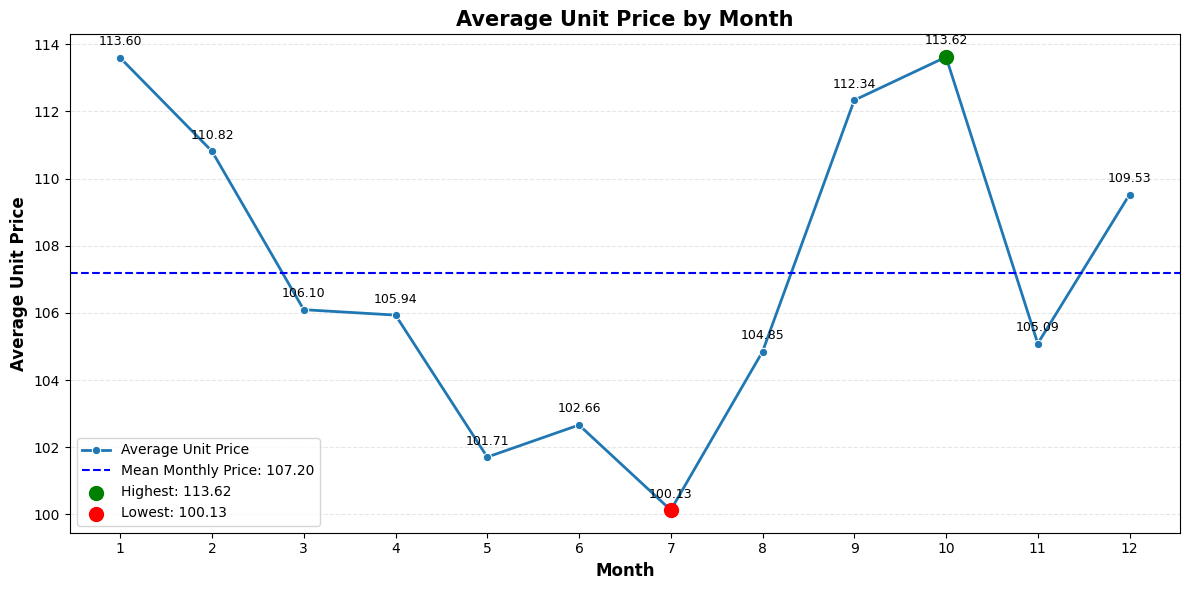

Highest average price: Month 10.0 | 113.62
Lowest average price: Month 7.0 | 100.13
Mean of monthly average prices: 107.20


In [43]:
# MONTHLY PRICING PATTERN

monthly = (
    df.groupby("month")
      .agg(
          avg_price=("unit_price", "mean"),
          avg_lag_price=("lag_price", "mean"),
          avg_qty=("qty", "mean"),
          total_qty=("qty", "sum"),
          avg_customers=("customers", "mean")
      )
      .reset_index()
      .sort_values("month")
)

display(monthly.round(2))

# Find highest, lowest, and overall average monthly price
max_idx = monthly["avg_price"].idxmax()
min_idx = monthly["avg_price"].idxmin()

high_month = monthly.loc[max_idx]
low_month = monthly.loc[min_idx]
overall_avg = monthly["avg_price"].mean()

# Plot
plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=monthly,
    x="month",
    y="avg_price",
    marker="o",
    linewidth=2,
    label="Average Unit Price"
)

# Label every monthly value
for _, row in monthly.iterrows():
    ax.annotate(
        f'{row["avg_price"]:.2f}',
        (row["month"], row["avg_price"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9
    )

# Overall average reference line
plt.axhline(
    overall_avg,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean Monthly Price: {overall_avg:.2f}"
)

# Highlight highest and lowest months
plt.scatter(
    high_month["month"], high_month["avg_price"],
    color="green", s=100, zorder=5,
    label=f'Highest: {high_month["avg_price"]:.2f}'
)

plt.scatter(
    low_month["month"], low_month["avg_price"],
    color="red", s=100, zorder=5,
    label=f'Lowest: {low_month["avg_price"]:.2f}'
)

plt.title(
    "Average Unit Price by Month",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.ylabel("Average Unit Price", fontsize=12, fontweight="bold")

plt.xticks(sorted(monthly["month"].dropna().unique()))
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Print high and low details
print(
    f'Highest average price: Month {high_month["month"]} '
    f'| {high_month["avg_price"]:.2f}'
)
print(
    f'Lowest average price: Month {low_month["month"]} '
    f'| {low_month["avg_price"]:.2f}'
)
print(f"Mean of monthly average prices: {overall_avg:.2f}")


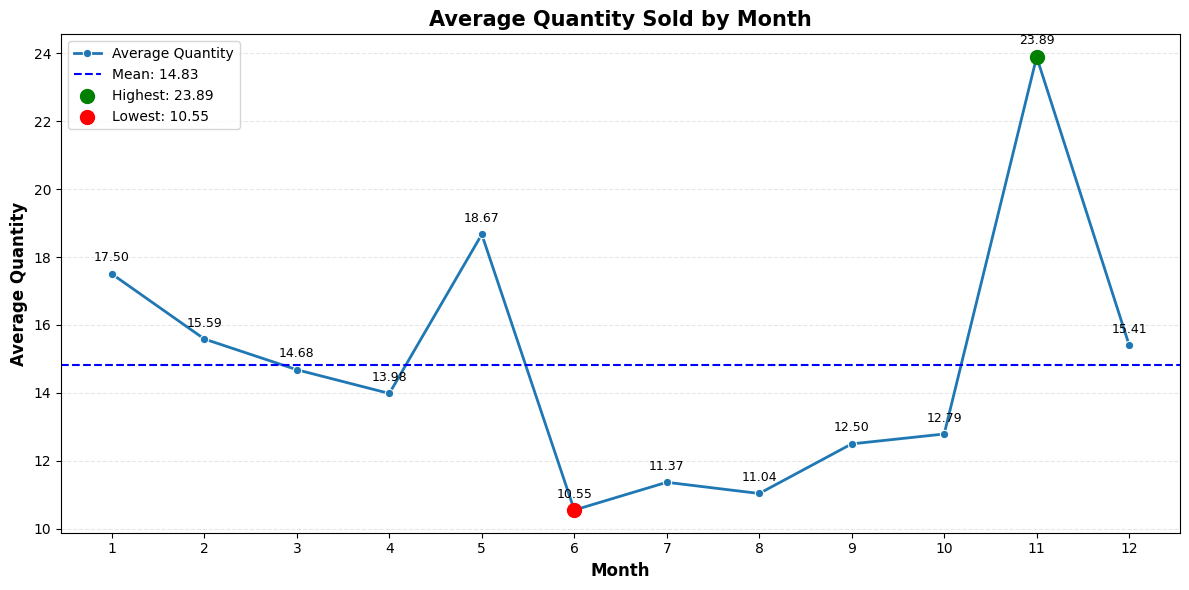

Highest average quantity: Month 11.0 | 23.89
Lowest average quantity: Month 6.0 | 10.55
Overall average of monthly quantities: 14.83


In [44]:
# MONTHLY SALES PATTERN

plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=monthly,
    x="month",
    y="avg_qty",
    marker="o",
    linewidth=2,
    label="Average Quantity"
)

# Calculate high, low, and average values
max_idx = monthly["avg_qty"].idxmax()
min_idx = monthly["avg_qty"].idxmin()

high_month = monthly.loc[max_idx]
low_month = monthly.loc[min_idx]
overall_avg = monthly["avg_qty"].mean()

# Label each month's value
for _, row in monthly.iterrows():
    ax.annotate(
        f'{row["avg_qty"]:.2f}',
        (row["month"], row["avg_qty"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9
    )

# Overall average line
plt.axhline(
    overall_avg,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {overall_avg:.2f}"
)

# Highlight highest and lowest months
plt.scatter(
    high_month["month"],
    high_month["avg_qty"],
    color="green",
    s=100,
    zorder=5,
    label=f'Highest: {high_month["avg_qty"]:.2f}'
)

plt.scatter(
    low_month["month"],
    low_month["avg_qty"],
    color="red",
    s=100,
    zorder=5,
    label=f'Lowest: {low_month["avg_qty"]:.2f}'
)

# Titles and labels
plt.title(
    "Average Quantity Sold by Month",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.ylabel("Average Quantity", fontsize=12, fontweight="bold")

plt.xticks(sorted(monthly["month"].dropna().unique()))
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Print high and low details
print(
    f'Highest average quantity: Month {high_month["month"]} '
    f'| {high_month["avg_qty"]:.2f}'
)
print(
    f'Lowest average quantity: Month {low_month["month"]} '
    f'| {low_month["avg_qty"]:.2f}'
)
print(f"Overall average of monthly quantities: {overall_avg:.2f}")


,holiday,avg_price,avg_qty,avg_customers,observations
0,0,97.0100,11.2900,73.2100,42
1,1,106.0100,12.7800,69.5600,386
2,2,112.0000,14.8800,82.0000,164
3,3,100.1700,22.4500,132.3500,40
4,4,105.0900,23.8900,138.8200,44


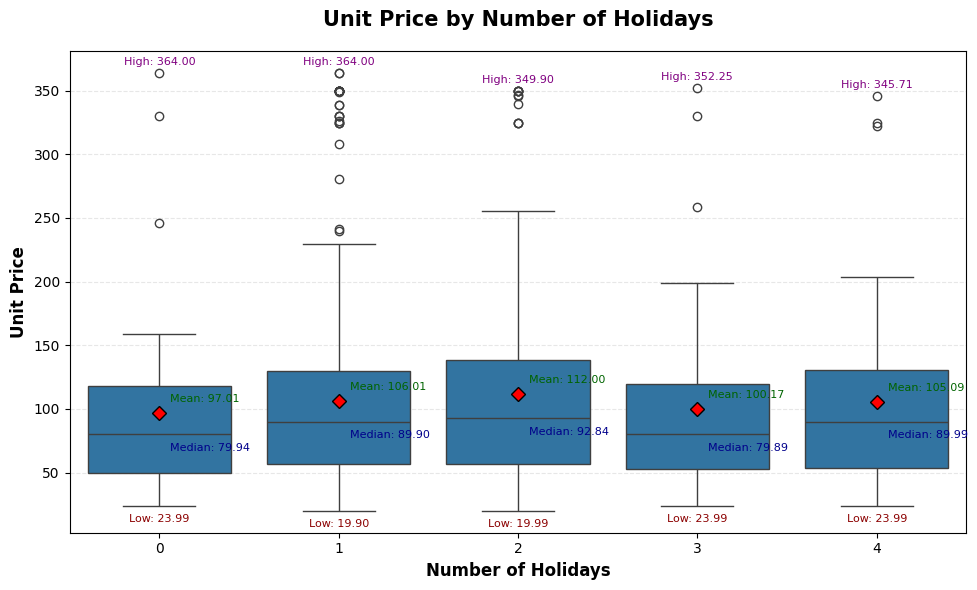

In [45]:
# HOLIDAY / WEEKEND CONTEXT

holiday_summary = (
    df.groupby("holiday")
      .agg(
          avg_price=("unit_price", "mean"),
          avg_qty=("qty", "mean"),
          avg_customers=("customers", "mean"),
          observations=("product_id", "size")
      )
      .reset_index()
)

display(holiday_summary.round(2))

# Boxplot
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df,
    x="holiday",
    y="unit_price",
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "red",
        "markeredgecolor": "black",
        "markersize": 7
    }
)

# Add mean, median, high, and low labels for each holiday group
for i, holiday_value in enumerate(holiday_summary["holiday"]):
    values = df.loc[
        df["holiday"] == holiday_value, "unit_price"
    ].dropna()

    if values.empty:
        continue

    mean_val = values.mean()
    median_val = values.median()
    min_val = values.min()
    max_val = values.max()

    ax.annotate(
        f"Mean: {mean_val:.2f}",
        xy=(i, mean_val),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=8,
        color="darkgreen"
    )

    ax.annotate(
        f"Median: {median_val:.2f}",
        xy=(i, median_val),
        xytext=(8, -12),
        textcoords="offset points",
        fontsize=8,
        color="darkblue"
    )

    ax.annotate(
        f"High: {max_val:.2f}",
        xy=(i, max_val),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="purple"
    )

    ax.annotate(
        f"Low: {min_val:.2f}",
        xy=(i, min_val),
        xytext=(0, -12),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="darkred"
    )

# Titles and labels
ax.set_title(
    "Unit Price by Number of Holidays",
    fontsize=15,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Number of Holidays", fontsize=12, fontweight="bold")
ax.set_ylabel("Unit Price", fontsize=12, fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


,year,avg_price,avg_lag_price,avg_qty,total_qty,avg_customers
0,2017,111.9500,112.3400,13.5500,4348,66.7900
1,2018,101.5700,102.9300,15.3500,5451,93.9000


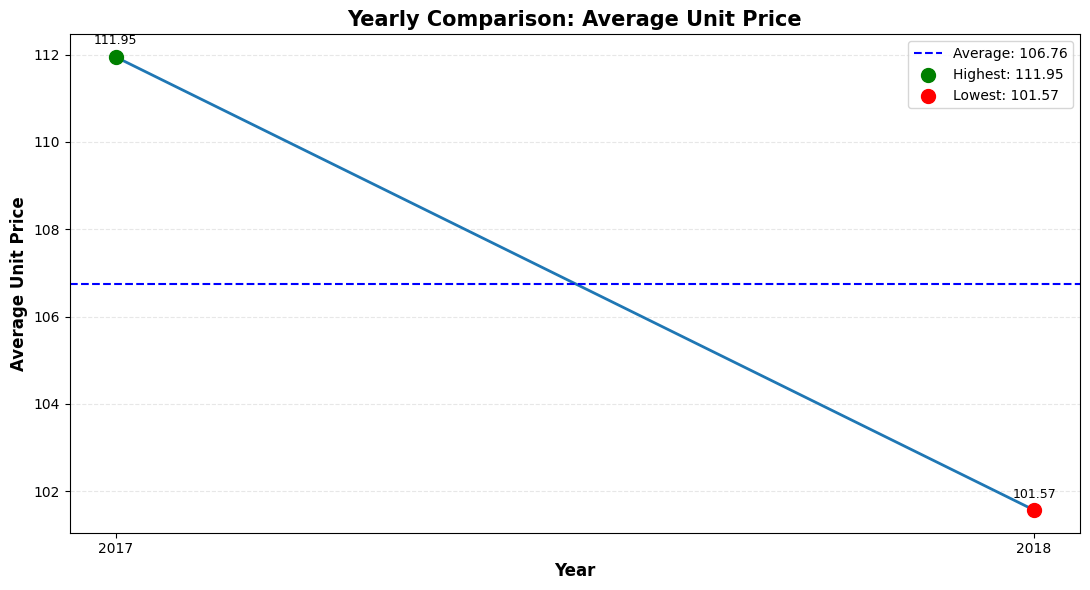

Highest: Year 2017.0 = 111.95
Lowest: Year 2018.0 = 101.57
Average across yearly values: 106.76


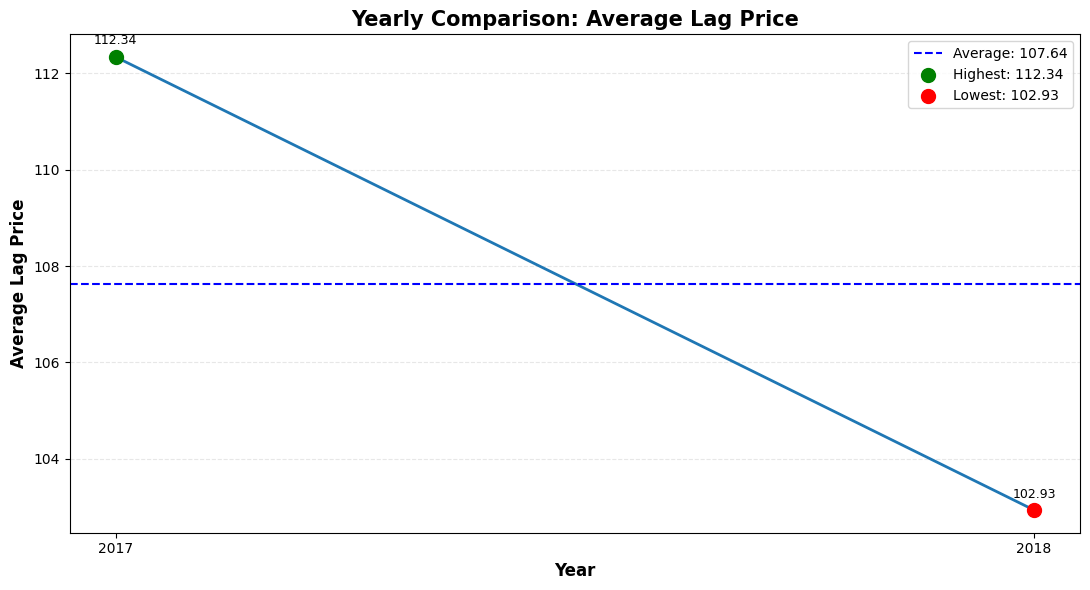

Highest: Year 2017.0 = 112.34
Lowest: Year 2018.0 = 102.93
Average across yearly values: 107.64


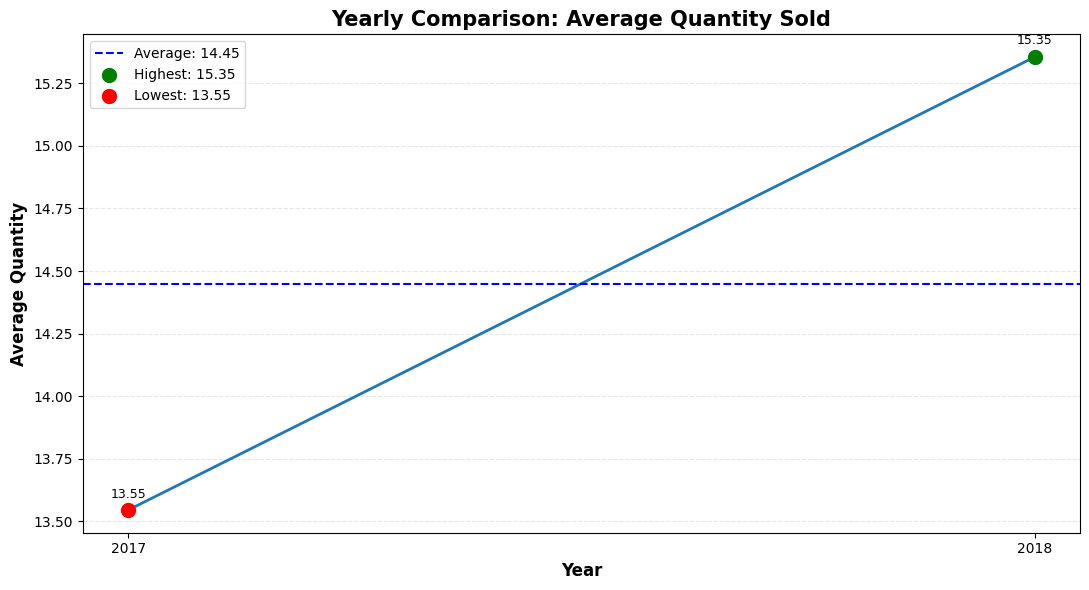

Highest: Year 2018.0 = 15.35
Lowest: Year 2017.0 = 13.55
Average across yearly values: 14.45


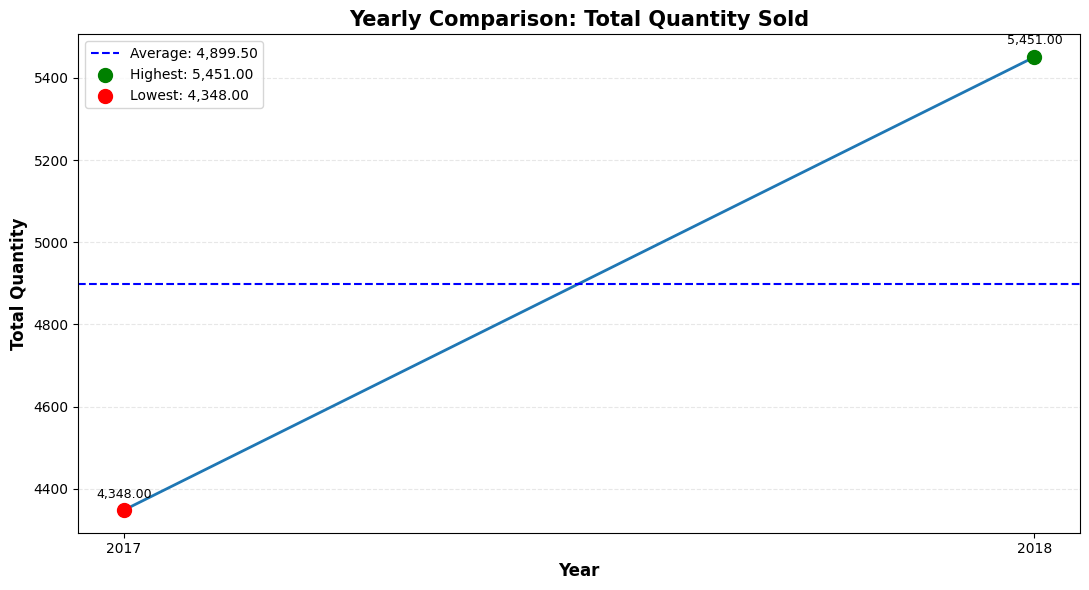

Highest: Year 2018.0 = 5,451.00
Lowest: Year 2017.0 = 4,348.00
Average across yearly values: 4,899.50


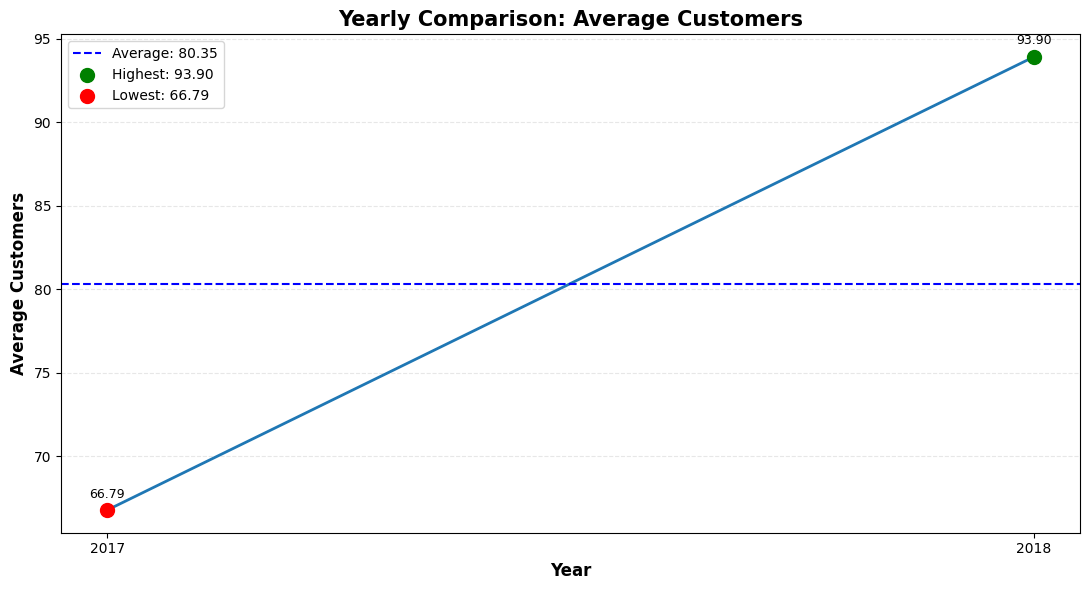

Highest: Year 2018.0 = 93.90
Lowest: Year 2017.0 = 66.79
Average across yearly values: 80.35


In [46]:
# YEARLY COMPARISON

year_summary = (
    df.groupby("year")
      .agg(
          avg_price=("unit_price", "mean"),
          avg_lag_price=("lag_price", "mean"),
          avg_qty=("qty", "mean"),
          total_qty=("qty", "sum"),
          avg_customers=("customers", "mean")
      )
      .reset_index()
      .sort_values("year")
)

display(year_summary.round(2))


# ------------------------------------------------------------
# Helper function: plot yearly values with labels and high/low
# ------------------------------------------------------------

def plot_yearly_comparison(data, column, title, ylabel):

    plot_data = data.dropna(subset=["year", column]).copy()

    if plot_data.empty:
        print(f"No valid data available for {column}")
        return

    max_idx = plot_data[column].idxmax()
    min_idx = plot_data[column].idxmin()

    high_year = plot_data.loc[max_idx]
    low_year = plot_data.loc[min_idx]
    avg_value = plot_data[column].mean()

    plt.figure(figsize=(11, 6))

    ax = sns.lineplot(
        data=plot_data,
        x="year",
        y=column,
        marker="o",
        linewidth=2
    )

    # Value labels for each year
    for _, row in plot_data.iterrows():
        ax.annotate(
            f'{row[column]:,.2f}',
            (row["year"], row[column]),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=9
        )

    # Average reference line
    plt.axhline(
        avg_value,
        color="blue",
        linestyle="--",
        linewidth=1.5,
        label=f"Average: {avg_value:,.2f}"
    )

    # Highlight highest and lowest values
    plt.scatter(
        high_year["year"],
        high_year[column],
        color="green",
        s=100,
        zorder=5,
        label=f'Highest: {high_year[column]:,.2f}'
    )

    plt.scatter(
        low_year["year"],
        low_year[column],
        color="red",
        s=100,
        zorder=5,
        label=f'Lowest: {low_year[column]:,.2f}'
    )

    plt.title(title, fontsize=15, fontweight="bold")
    plt.xlabel("Year", fontsize=12, fontweight="bold")
    plt.ylabel(ylabel, fontsize=12, fontweight="bold")
    plt.xticks(plot_data["year"].unique())
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Highest: Year {high_year['year']} = {high_year[column]:,.2f}")
    print(f"Lowest: Year {low_year['year']} = {low_year[column]:,.2f}")
    print(f"Average across yearly values: {avg_value:,.2f}")


# ------------------------------------------------------------
# Yearly plots
# ------------------------------------------------------------

plot_yearly_comparison(
    year_summary,
    "avg_price",
    "Yearly Comparison: Average Unit Price",
    "Average Unit Price"
)

plot_yearly_comparison(
    year_summary,
    "avg_lag_price",
    "Yearly Comparison: Average Lag Price",
    "Average Lag Price"
)

plot_yearly_comparison(
    year_summary,
    "avg_qty",
    "Yearly Comparison: Average Quantity Sold",
    "Average Quantity"
)

plot_yearly_comparison(
    year_summary,
    "total_qty",
    "Yearly Comparison: Total Quantity Sold",
    "Total Quantity"
)

plot_yearly_comparison(
    year_summary,
    "avg_customers",
    "Yearly Comparison: Average Customers",
    "Average Customers"
)


,s
count,676.0000
mean,14.6400
std,11.9300
min,0.4800
25%,7.5100
50%,11.3200
75%,17.7500
max,100.0000


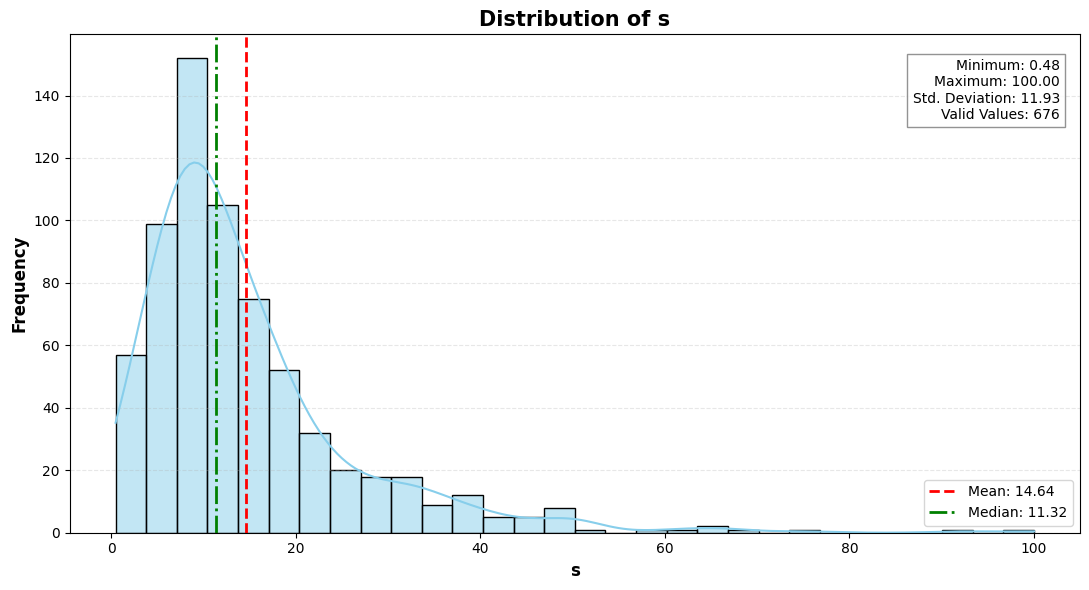

Mean of s: 14.64
Median of s: 11.32
Standard deviation of s: 11.93
Minimum value: 0.48
Maximum value: 100.00

Note: `s` is treated as a seasonality-related variable, but its exact calculation is undocumented. Its meaning should be verified before drawing business conclusions.


In [47]:
# THE `s` VARIABLE

# Summary statistics
display(df["s"].describe().to_frame("s").round(2))

# Calculate statistics
s_values = df["s"].dropna()

mean_s = s_values.mean()
median_s = s_values.median()
std_s = s_values.std()
min_s = s_values.min()
max_s = s_values.max()

# Distribution plot
plt.figure(figsize=(11, 6))

ax = sns.histplot(
    s_values,
    kde=True,
    bins=30,
    color="skyblue",
    edgecolor="black"
)

# Mean and median reference lines
plt.axvline(
    mean_s,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_s:.2f}"
)

plt.axvline(
    median_s,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_s:.2f}"
)

# Add summary information to the plot
plt.text(
    0.98, 0.95,
    f"Minimum: {min_s:.2f}\n"
    f"Maximum: {max_s:.2f}\n"
    f"Std. Deviation: {std_s:.2f}\n"
    f"Valid Values: {len(s_values)}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        alpha=0.85,
        edgecolor="gray"
    )
)

# Titles and labels
plt.title(
    "Distribution of s",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("s", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Print interpretation statistics
print(f"Mean of s: {mean_s:.2f}")
print(f"Median of s: {median_s:.2f}")
print(f"Standard deviation of s: {std_s:.2f}")
print(f"Minimum value: {min_s:.2f}")
print(f"Maximum value: {max_s:.2f}")

print(
    "\nNote: `s` is treated as a seasonality-related variable, "
    "but its exact calculation is undocumented. "
    "Its meaning should be verified before drawing business conclusions."
)


# FEATURE ENGINEERING
Competitor positioning

Rating positioning

Freight positioning

Time features

In [48]:
# COMPETITOR PRICE FEATURES


competitor_price_cols = ["comp_1", "comp_2", "comp_3"]

df["competitor_price_mean"] = df[competitor_price_cols].mean(axis=1)
df["competitor_price_min"] = df[competitor_price_cols].min(axis=1)
df["competitor_price_max"] = df[competitor_price_cols].max(axis=1)

df["price_gap_mean"] = (
    df["unit_price"] - df["competitor_price_mean"]
)

df["price_gap_min"] = (
    df["unit_price"] - df["competitor_price_min"]
)

df["price_gap_max"] = (
    df["unit_price"] - df["competitor_price_max"]
)

df["price_ratio_mean"] = (
    df["unit_price"] / df["competitor_price_mean"].replace(0, np.nan)
)

display(
    df[
        ["unit_price", "competitor_price_mean",
         "competitor_price_min", "competitor_price_max",
         "price_gap_mean", "price_ratio_mean"]
    ].head()
)


,unit_price,competitor_price_mean,competitor_price_min,competitor_price_max,price_gap_mean,price_ratio_mean
0,45.9500,116.9500,45.9500,215.0000,-71.0000,0.3929
1,45.9500,114.9500,45.9500,209.0000,-69.0000,0.3997
2,45.9500,113.6167,45.9500,205.0000,-67.6667,0.4044
3,45.9500,111.7866,45.9500,199.5098,-65.8366,0.4111
4,45.9500,99.7496,45.9500,163.3987,-53.7996,0.4607


In [49]:
# COMPETITOR RATING FEATURES

competitor_rating_cols = ["ps1", "ps2", "ps3"]

df["competitor_score_mean"] = df[competitor_rating_cols].mean(axis=1)

df["score_gap_vs_competitors"] = (
    df["product_score"] - df["competitor_score_mean"]
)

display(
    df[
        ["product_score", "competitor_score_mean",
         "score_gap_vs_competitors"]
    ].head()
)


,product_score,competitor_score_mean,score_gap_vs_competitors
0,4.0000,4.1000,-0.1000
1,4.0000,4.1000,-0.1000
2,4.0000,4.1000,-0.1000
3,4.0000,4.1000,-0.1000
4,4.0000,4.1000,-0.1000


In [50]:
# FREIGHT POSITIONING FEATURES

competitor_freight_cols = ["fp1", "fp2", "fp3"]

df["competitor_freight_mean"] = df[competitor_freight_cols].mean(axis=1)

df["freight_gap_vs_competitors"] = (
    df["freight_price"] - df["competitor_freight_mean"]
)

display(
    df[
        ["freight_price", "competitor_freight_mean",
         "freight_gap_vs_competitors"]
    ].head()
)


,freight_price,competitor_freight_mean,freight_gap_vs_competitors
0,15.1000,12.9573,2.1427
1,12.9333,16.3415,-3.4082
2,14.8400,17.0099,-2.1699
3,14.2875,16.1190,-1.8315
4,15.1000,19.4004,-4.3004


In [51]:
# TIME FEATURES

df["quarter"] = df["date"].dt.quarter
df["time_index"] = (
    (df["date"].dt.year - df["date"].dt.year.min()) * 12
    + df["date"].dt.month
)

# Cyclical month representation
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

display(
    df[
        ["date", "month", "year", "quarter",
         "time_index", "month_sin", "month_cos"]
    ].head(12)
)


,date,month,year,quarter,time_index,month_sin,month_cos
0,2017-05-01,5,2017,2,5,0.5000,-0.8660
1,2017-06-01,6,2017,2,6,0.0000,-1.0000
2,2017-07-01,7,2017,3,7,-0.5000,-0.8660
3,2017-08-01,8,2017,3,8,-0.8660,-0.5000
4,2017-09-01,9,2017,3,9,-1.0000,-0.0000
5,2017-10-01,10,2017,4,10,-0.8660,0.5000
6,2017-11-01,11,2017,4,11,-0.5000,0.8660
7,2017-12-01,12,2017,4,12,-0.0000,1.0000
8,2018-01-01,1,2018,1,13,0.5000,0.8660
9,2018-02-01,2,2018,1,14,0.8660,0.5000


# CORRELATION / RELATIONSHIP REVIEW
Correlation is useful for screening relationships, but it is not causal evidence.

We will inspect relationships among the target, pricing, sales, competitor and product variables.

,correlation_with_lag_price
lag_price,1.0000
previous_unit_price,0.9988
unit_price,0.9945
price_gap_min,0.8669
price_gap_mean,0.8403
gap_comp_1,0.7929
gap_comp_3,0.7884
gap_comp_2,0.7664
price_ratio_mean,0.7548
ratio_comp_3,0.7312


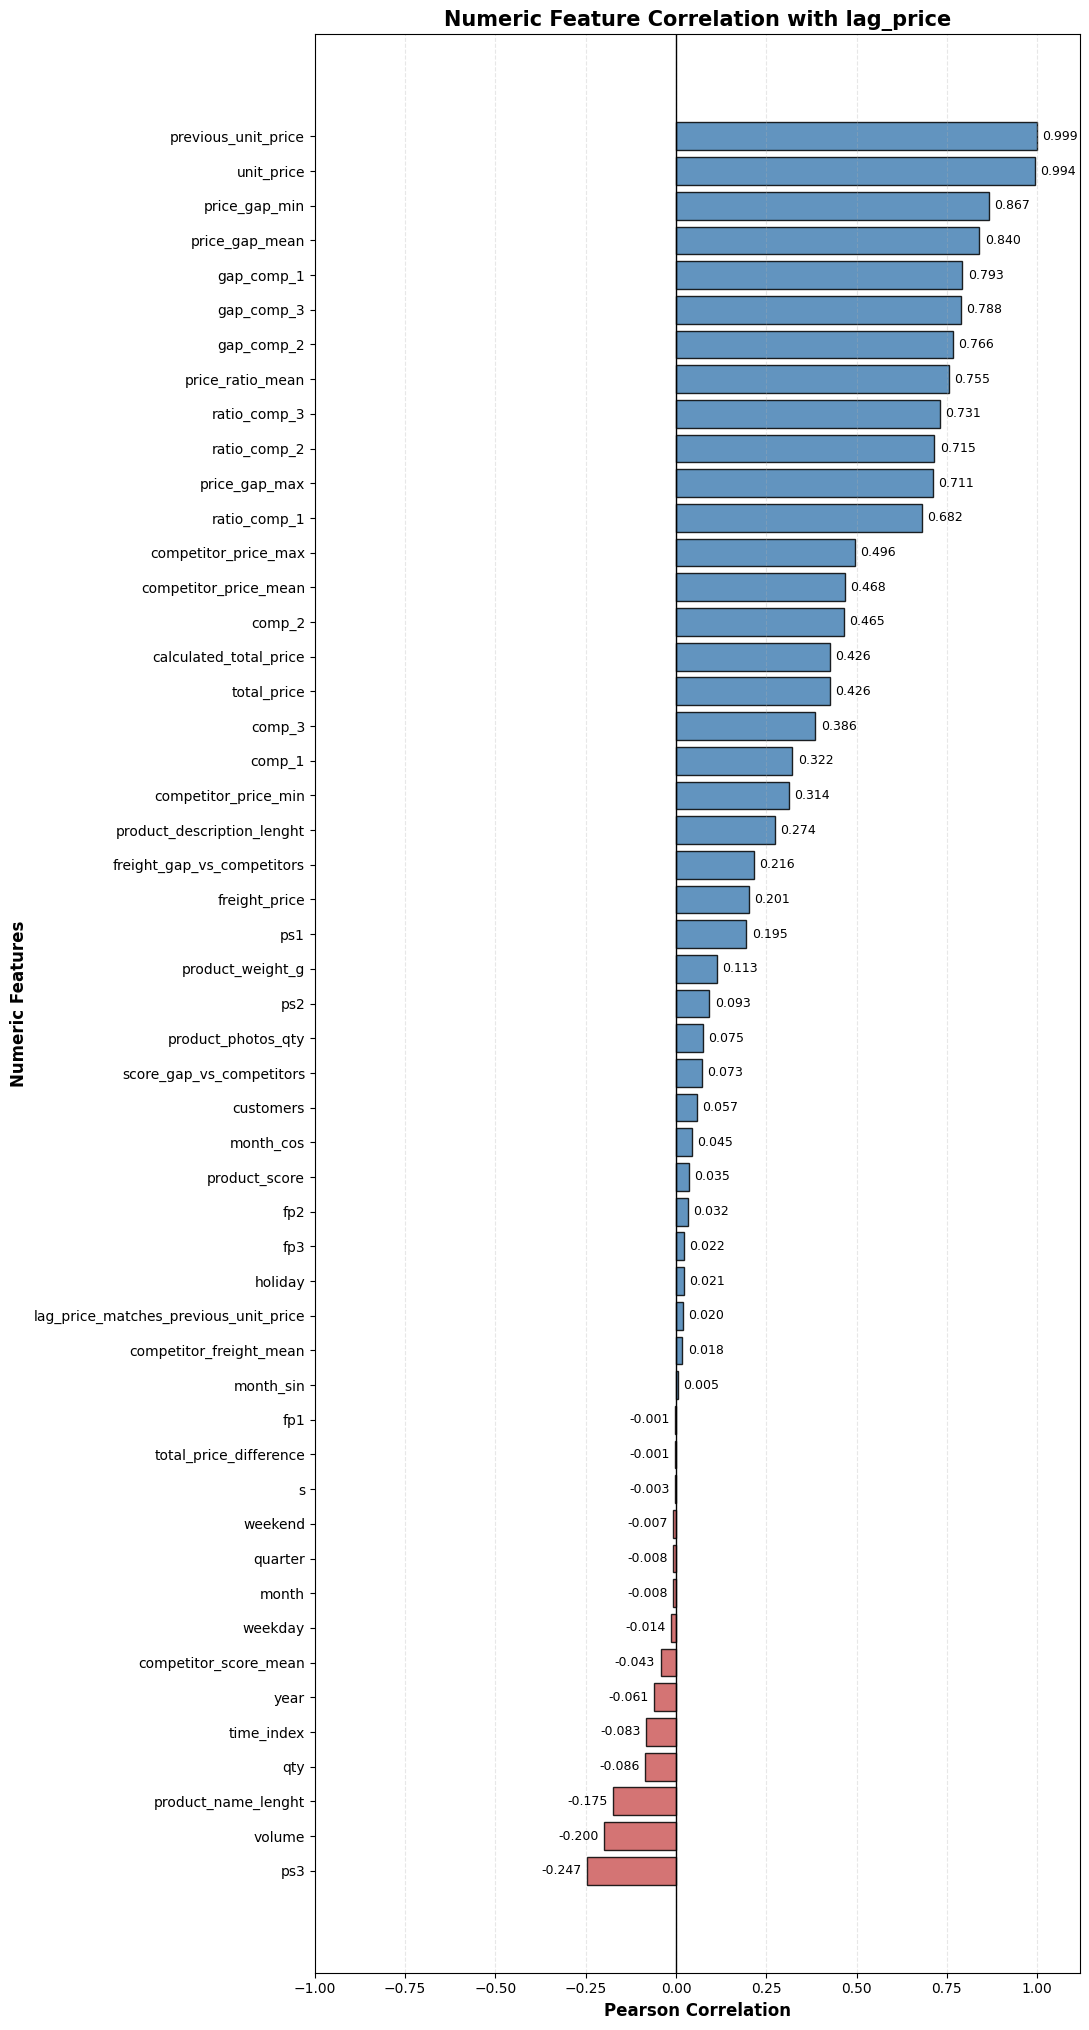

Top 5 positive correlations with lag_price:


,correlation
previous_unit_price,0.9988
unit_price,0.9945
price_gap_min,0.8669
price_gap_mean,0.8403
gap_comp_1,0.7929


Top 5 negative correlations with lag_price:


,correlation
ps3,-0.2470
volume,-0.2001
product_name_lenght,-0.1749
qty,-0.0859
time_index,-0.0828


In [52]:
# CORRELATION WITH TARGET

target_corr = (
    df.select_dtypes(include=np.number)
      .corr()["lag_price"]
      .sort_values(ascending=False)
)

# Display correlation table
display(target_corr.to_frame("correlation_with_lag_price").round(4))

# Remove target's self-correlation from the plot
plot_corr = target_corr.drop("lag_price", errors="ignore").dropna()

# Sort by correlation for clearer visualization
plot_corr = plot_corr.sort_values()

# Assign colors based on positive and negative correlation
colors = [
    "steelblue" if value >= 0 else "indianred"
    for value in plot_corr.values
]

# Plot
plt.figure(figsize=(11, max(6, len(plot_corr) * 0.4)))

bars = plt.barh(
    plot_corr.index,
    plot_corr.values,
    color=colors,
    edgecolor="black",
    alpha=0.85
)

# Zero reference line
plt.axvline(0, color="black", linewidth=1)

# Add correlation value labels
for bar, value in zip(bars, plot_corr.values):
    offset = 0.015 if value >= 0 else -0.015

    plt.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

plt.title(
    "Numeric Feature Correlation with lag_price",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Pearson Correlation", fontsize=12, fontweight="bold")
plt.ylabel("Numeric Features", fontsize=12, fontweight="bold")

plt.xlim(
    min(-1, plot_corr.min() - 0.12),
    max(1, plot_corr.max() + 0.12)
)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# Display strongest relationships, excluding the target itself
print("Top 5 positive correlations with lag_price:")
display(
    target_corr.drop("lag_price", errors="ignore")
               .dropna()
               .sort_values(ascending=False)
               .head(5)
               .to_frame("correlation")
               .round(4)
)

print("Top 5 negative correlations with lag_price:")
display(
    target_corr.drop("lag_price", errors="ignore")
               .dropna()
               .sort_values()
               .head(5)
               .to_frame("correlation")
               .round(4)
)


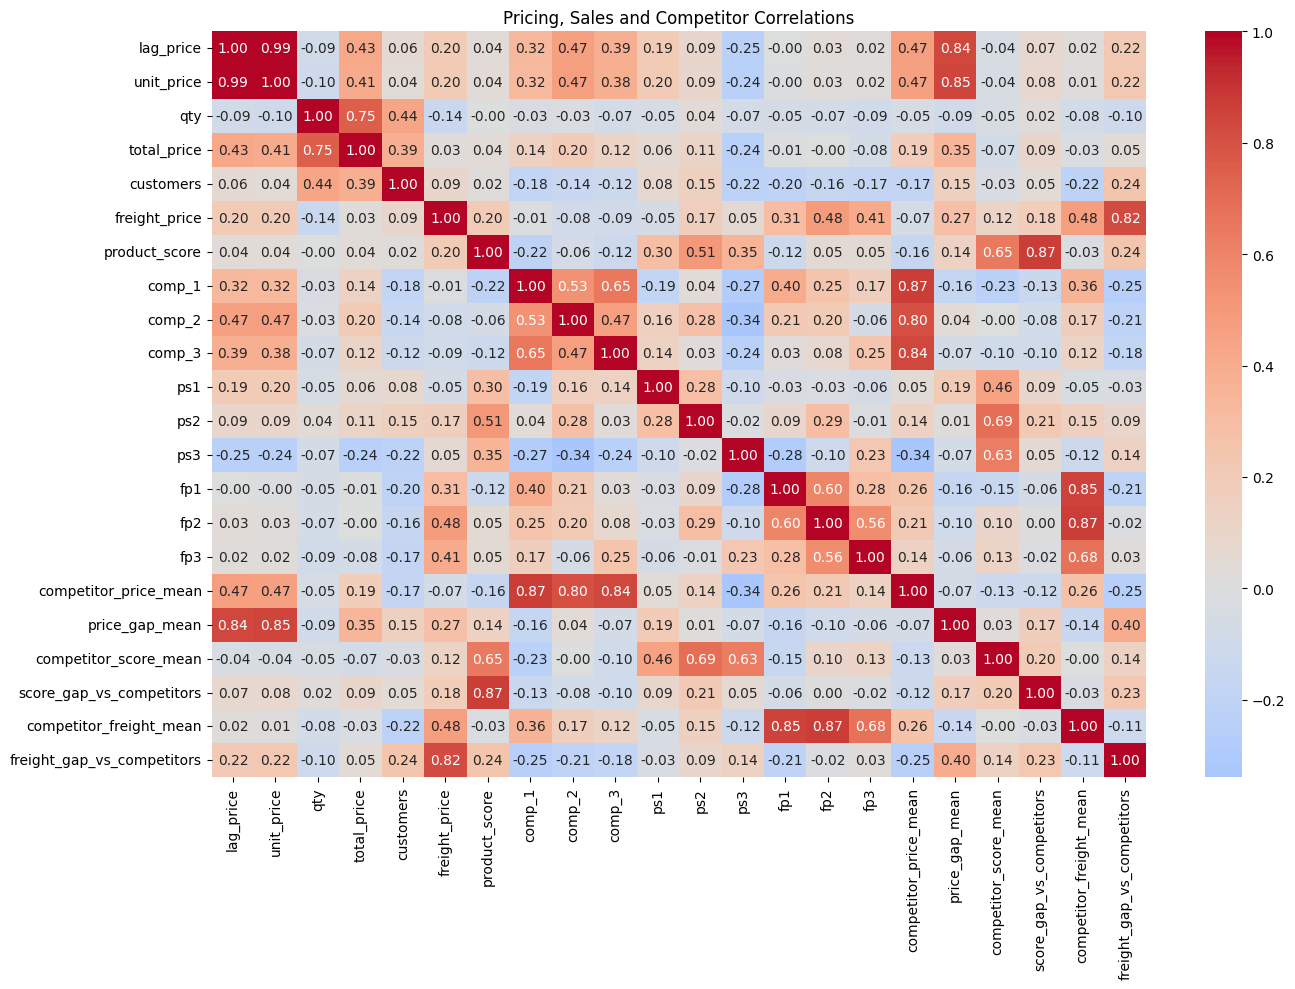

In [53]:
# TOP NUMERICAL RELATIONSHIPS HEATMAP

corr_cols = [
    "lag_price", "unit_price", "qty", "total_price",
    "customers", "freight_price",
    "product_score",
    "comp_1", "comp_2", "comp_3",
    "ps1", "ps2", "ps3",
    "fp1", "fp2", "fp3",
    "competitor_price_mean",
    "price_gap_mean",
    "competitor_score_mean",
    "score_gap_vs_competitors",
    "competitor_freight_mean",
    "freight_gap_vs_competitors"
]

plt.figure(figsize=(14, 10))
sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Pricing, Sales and Competitor Correlations")
plt.tight_layout()
plt.show()


# OUTLIER REVIEW
We use the IQR rule only as a screening tool.

An IQR outlier is not automatically removed. We inspect it and decide whether it is a valid business observation or a data problem.

In [54]:
# IQR OUTLIER COUNTS

numeric_for_outliers = [
    "qty", "total_price", "freight_price", "unit_price",
    "product_description_lenght", "product_photos_qty",
    "product_weight_g", "product_score", "customers",
    "s", "volume", "comp_1", "ps1", "fp1",
    "comp_2", "ps2", "fp2", "comp_3", "ps3", "fp3",
    "lag_price"
]

outlier_rows = []

for col in numeric_for_outliers:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(count),
        "outlier_percent": round(count / len(df) * 100, 2)
    })

outlier_report = (
    pd.DataFrame(outlier_rows)
      .sort_values("outlier_count", ascending=False)
)

display(outlier_report)


,column,lower_bound,upper_bound,outlier_count,outlier_percent
15,ps2,3.9500,4.3500,156,23.0800
18,ps3,3.6000,4.4000,121,17.9000
6,product_weight_g,"-1,905.0000","4,103.0000",117,17.3100
13,fp1,4.9673,28.5916,96,14.2000
4,product_description_lenght,-507.0000,"1,749.0000",91,13.4600
5,product_photos_qty,-0.5000,3.5000,87,12.8700
12,ps1,3.9500,4.3500,79,11.6900
2,freight_price,2.8344,34.6410,76,11.2400
17,comp_3,-15.5207,169.2964,58,8.5800
9,s,-7.8430,33.0990,53,7.8400


# LEAKAGE ASSESSMENT
flag potential leakage rather than silently using every column.

In [55]:
# LEAKAGE REVIEW

leakage_review = pd.DataFrame({
    "feature": [
        "unit_price",
        "total_price",
        "qty",
        "customers",
        "comp_1", "comp_2", "comp_3",
        "freight_price",
        "fp1", "fp2", "fp3",
        "product_score",
        "product_category_name",
        "product_id",
        "month_year",
        "lag_price"
    ],
    "reason_to_review": [
        "Current-period price may occur after the previous price target.",
        "Current-period sales value may be an outcome observed after pricing.",
        "Current-period quantity sold may be unavailable before the period occurs.",
        "Current-period customer count may be unavailable before the period occurs.",
        "Competitor price availability depends on the prediction moment.",
        "Competitor price availability depends on the prediction moment.",
        "Competitor price availability depends on the prediction moment.",
        "Current-period freight may depend on the observed sale.",
        "Competitor freight availability depends on timing.",
        "Competitor freight availability depends on timing.",
        "Competitor freight availability depends on timing.",
        "Product-level attribute; generally less time-sensitive.",
        "Product-level/category information.",
        "Identifier; must be encoded carefully if used.",
        "Known time context.",
        "Assigned target; never use as an input feature."
    ]
})

display(leakage_review)


,feature,reason_to_review
0,unit_price,Current-period price may occur after the previ...
1,total_price,Current-period sales value may be an outcome o...
2,qty,Current-period quantity sold may be unavailabl...
3,customers,Current-period customer count may be unavailab...
4,comp_1,Competitor price availability depends on the p...
5,comp_2,Competitor price availability depends on the p...
6,comp_3,Competitor price availability depends on the p...
7,freight_price,Current-period freight may depend on the obser...
8,fp1,Competitor freight availability depends on tim...
9,fp2,Competitor freight availability depends on tim...


# Chronological train/test preparation

In [56]:
# CHRONOLOGICAL TRAIN/TEST PREPARATION

model_df = df.sort_values("date").reset_index(drop=True).copy()

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTarget mean:")
print("Train:", train_df["lag_price"].mean())
print("Test :", test_df["lag_price"].mean())


Training rows: 540
Testing rows: 136

Training period:
2017-01-01 00:00:00 to 2018-05-01 00:00:00

Testing period:
2018-05-01 00:00:00 to 2018-08-01 00:00:00

Target mean:
Train: 110.00440864040742
Test : 97.05739710948531


# Candidate feature inventory — BEFORE modeling

In [57]:
# FINAL DATASET SNAPSHOT FOR MODELING STAGE

print("Final working dataset shape:", df.shape)

print("\nColumns created during preprocessing/feature engineering:")
new_columns = [
    "date",
    "calculated_total_price",
    "total_price_difference",
    "total_price_matches",
    "previous_unit_price",
    "lag_price_matches_previous_unit_price",
    "gap_comp_1", "gap_comp_2", "gap_comp_3",
    "ratio_comp_1", "ratio_comp_2", "ratio_comp_3",
    "competitor_price_mean",
    "competitor_price_min",
    "competitor_price_max",
    "price_gap_mean",
    "price_gap_min",
    "price_gap_max",
    "price_ratio_mean",
    "competitor_score_mean",
    "score_gap_vs_competitors",
    "competitor_freight_mean",
    "freight_gap_vs_competitors",
    "quarter",
    "time_index",
    "month_sin",
    "month_cos"
]

display(
    [c for c in new_columns if c in df.columns]
)

print("\nReady for model-selection stage")


Final working dataset shape: (676, 57)

Columns created during preprocessing/feature engineering:


['date',
 'calculated_total_price',
 'total_price_difference',
 'total_price_matches',
 'previous_unit_price',
 'lag_price_matches_previous_unit_price',
 'gap_comp_1',
 'gap_comp_2',
 'gap_comp_3',
 'ratio_comp_1',
 'ratio_comp_2',
 'ratio_comp_3',
 'competitor_price_mean',
 'competitor_price_min',
 'competitor_price_max',
 'price_gap_mean',
 'price_gap_min',
 'price_gap_max',
 'price_ratio_mean',
 'competitor_score_mean',
 'score_gap_vs_competitors',
 'competitor_freight_mean',
 'freight_gap_vs_competitors',
 'quarter',
 'time_index',
 'month_sin',
 'month_cos']


Ready for model-selection stage


# Finalize future set

In [58]:
# FINALIZE THE FEATURE SET

target = "lag_price"

# CATEGORICAL FEATURES

categorical_features = [
    "product_id",
    "product_category_name"
]


# NUMERICAL FEATURES

numerical_features = [
    # Time
    "month",
    "year",
    "quarter",
    "weekday",
    "weekend",
    "holiday",
    "time_index",
    "month_sin",
    "month_cos",

    # Product attributes
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_score",
    "volume",

    # Competitor prices
    "comp_1",
    "comp_2",
    "comp_3",
    "competitor_price_mean",
    "competitor_price_min",
    "competitor_price_max",

    # Competitor scores
    "ps1",
    "ps2",
    "ps3",
    "competitor_score_mean",
    "score_gap_vs_competitors",

    # Competitor freight
    "fp1",
    "fp2",
    "fp3",
    "competitor_freight_mean",

    # Seasonality-related variable
    "s"
]

# FINAL FEATURE LIST

feature_columns = categorical_features + numerical_features

print("Number of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))
print("Total input features:", len(feature_columns))

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Number of categorical features: 2
Number of numerical features: 31
Total input features: 33

Categorical features:
['product_id', 'product_category_name']

Numerical features:
['month', 'year', 'quarter', 'weekday', 'weekend', 'holiday', 'time_index', 'month_sin', 'month_cos', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_score', 'volume', 'comp_1', 'comp_2', 'comp_3', 'competitor_price_mean', 'competitor_price_min', 'competitor_price_max', 'ps1', 'ps2', 'ps3', 'competitor_score_mean', 'score_gap_vs_competitors', 'fp1', 'fp2', 'fp3', 'competitor_freight_mean', 's']


In [59]:
# Check for missing features in the dataset

missing_features = [
    col for col in feature_columns
    if col not in df.columns
]

if missing_features:
    print("Missing features:")
    print(missing_features)
else:
    print("All selected features are available in the dataset.")

print("\nFinal feature count:", len(feature_columns))

All selected features are available in the dataset.

Final feature count: 33


In [60]:
# CREATE X AND y

X = df[feature_columns].copy()
y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())
display(y.head())

X shape: (676, 33)
y shape: (676,)


,product_id,product_category_name,month,year,quarter,weekday,weekend,holiday,time_index,month_sin,month_cos,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,volume,comp_1,comp_2,comp_3,competitor_price_mean,competitor_price_min,competitor_price_max,ps1,ps2,ps3,competitor_score_mean,score_gap_vs_competitors,fp1,fp2,fp3,competitor_freight_mean,s
0,bed1,bed_bath_table,5,2017,2,23,8,1,5,0.5000,-0.8660,39,161,2,350,4.0000,3800,89.9000,215.0000,45.9500,116.9500,45.9500,215.0000,3.9000,4.4000,4.0000,4.1000,-0.1000,15.0119,8.7600,15.1000,12.9573,10.2674
1,bed1,bed_bath_table,6,2017,2,22,8,1,6,0.0000,-1.0000,39,161,2,350,4.0000,3800,89.9000,209.0000,45.9500,114.9500,45.9500,209.0000,3.9000,4.4000,4.0000,4.1000,-0.1000,14.7692,21.3220,12.9333,16.3415,6.5031
2,bed1,bed_bath_table,7,2017,3,21,10,1,7,-0.5000,-0.8660,39,161,2,350,4.0000,3800,89.9000,205.0000,45.9500,113.6167,45.9500,205.0000,3.9000,4.4000,4.0000,4.1000,-0.1000,13.9938,22.1959,14.8400,17.0099,12.0717
3,bed1,bed_bath_table,8,2017,3,23,8,1,8,-0.8660,-0.5000,39,161,2,350,4.0000,3800,89.9000,199.5098,45.9500,111.7866,45.9500,199.5098,3.9000,4.4000,4.0000,4.1000,-0.1000,14.6568,19.4129,14.2875,16.1190,9.2939
4,bed1,bed_bath_table,9,2017,3,21,9,1,9,-1.0000,-0.0000,39,161,2,350,4.0000,3800,89.9000,163.3987,45.9500,99.7496,45.9500,163.3987,3.9000,4.4000,4.0000,4.1000,-0.1000,18.7765,24.3247,15.1000,19.4004,5.5556


0   45.9000
1   45.9500
2   45.9500
3   45.9500
4   45.9500
Name: lag_price, dtype: float64

In [61]:
# create a chronological train/test split based on unique dates

model_df = df.sort_values("date").reset_index(drop=True).copy()

unique_dates = sorted(model_df["date"].unique())

split_date_index = int(len(unique_dates) * 0.80)

train_dates = unique_dates[:split_date_index]
test_dates = unique_dates[split_date_index:]

train_df = model_df[
    model_df["date"].isin(train_dates)
].copy()

test_df = model_df[
    model_df["date"].isin(test_dates)
].copy()


print("Number of unique months:", len(unique_dates))
print("Training months:", len(train_dates))
print("Testing months:", len(test_dates))

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nTraining shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Number of unique months: 20
Training months: 16
Testing months: 4

Training period:
2017-01-01 00:00:00 to 2018-04-01 00:00:00

Testing period:
2018-05-01 00:00:00 to 2018-08-01 00:00:00

Training shape: (516, 57)
Testing shape: (160, 57)


In [62]:
# CREATE TRAIN / TEST DATA

X_train = train_df[feature_columns].copy()
y_train = train_df[target].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train: (516, 33)
y_train: (516,)
X_test : (160, 33)
y_test : (160,)


In [63]:
X_train.head()

,product_id,product_category_name,month,year,quarter,weekday,weekend,holiday,time_index,month_sin,month_cos,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,volume,comp_1,comp_2,comp_3,competitor_price_mean,competitor_price_min,competitor_price_max,ps1,ps2,ps3,competitor_score_mean,score_gap_vs_competitors,fp1,fp2,fp3,competitor_freight_mean,s
0,health5,health_beauty,1,2017,1,22,9,1,1,0.5000,0.8660,51,625,1,900,4.3000,11400,349.9000,349.9000,64.9900,254.9300,64.9900,349.9000,4.3000,4.3000,3.9000,4.1667,0.1333,22.9013,22.9013,11.0600,18.9542,12.7717
1,health7,health_beauty,1,2017,1,22,9,1,1,0.5000,0.8660,59,492,2,200,3.9000,3960,64.9900,64.9900,64.9900,64.9900,64.9900,64.9900,3.9000,3.9000,3.9000,3.9000,0.0000,11.0600,11.0600,11.0600,11.0600,5.6429
2,health9,health_beauty,2,2017,1,20,8,2,2,0.8660,0.5000,48,575,1,100,4.3000,4500,19.9900,19.9900,64.9900,34.9900,19.9900,64.9900,4.3000,4.3000,3.9000,4.1667,0.1333,11.7509,11.7509,15.3480,12.9499,14.9444
3,garden8,garden_tools,2,2017,1,20,8,2,2,0.8660,0.5000,33,2188,2,7650,4.2000,8000,179.9900,179.9900,179.9900,179.9900,179.9900,179.9900,4.2000,4.2000,4.2000,4.2000,0.0000,33.5400,33.5400,33.5400,33.5400,8.9423
4,health5,health_beauty,2,2017,1,20,8,2,2,0.8660,0.5000,51,625,1,900,4.3000,11400,19.9900,349.9000,64.9900,144.9600,19.9900,349.9000,4.3000,4.3000,3.9000,4.1667,0.1333,11.7509,26.9275,15.3480,18.0088,11.2772


In [64]:
# verify that the train/test split is chronological and there is no temporal overlap

train_max_date = train_df["date"].max()
test_min_date = test_df["date"].min()

print("Last training date :", train_max_date)
print("First testing date :", test_min_date)

if train_max_date < test_min_date:
    print("\n✓ Chronological split verified.")
else:
    print("\n✗ Temporal overlap detected.")

Last training date : 2018-04-01 00:00:00
First testing date : 2018-05-01 00:00:00

✓ Chronological split verified.


# ENCODE CATEGORICAL VARIABLES
For product_id and product_category_name, we'll use One-Hot Encoding.

In [65]:
# CATEGORICAL ENCODER PIPELINE

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

print("Categorical encoder created.")

Categorical encoder created.


# NUMERICAL PREPROCESSING
For Ridge, scaling is required.

For Random Forest, scaling is not required.

So we create two separate preprocessing pipelines.

In [66]:
# NUMERICAL TRANSFORMER PIPELINE

ridge_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [67]:
# Random Forest numeric transformer pipeline

rf_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

In [68]:
# RIDGE PREPROCESSOR

ridge_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            ridge_numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Ridge preprocessor created.")

Ridge preprocessor created.


In [69]:
# RANDOM FOREST PREPROCESSOR

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            rf_numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Random Forest preprocessor created.")

Random Forest preprocessor created.


# BUILD RIDGE MODEL

In [70]:
# RIDGE REGRESSION

ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            ridge_preprocessor
        ),
        (
            "model",
            Ridge(alpha=0.1)
        )
    ]
)

print("Ridge model created.")

Ridge model created.


In [71]:
# TRAIN THE RIDGE MODEL

ridge_model.fit(X_train, y_train)

print("Ridge model trained successfully.")

Ridge model trained successfully.


In [72]:
# MAKE PREDICTIONS WITH RIDGE MODEL

ridge_predictions = ridge_model.predict(X_test)

print("First 10 Ridge predictions:")
print(ridge_predictions[:10])

First 10 Ridge predictions:
[155.14407845 113.60737062 216.93070584 347.11332098 183.8630091
  25.97556318  49.37834762 143.59116841  25.81734064  62.43439177]


In [208]:
# RIDGE MODEL EVALUATION

ridge_mae = mean_absolute_error(y_test,ridge_predictions)
ridge_mse = mean_squared_error(y_test,ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test,ridge_predictions)
ridge_mape = mean_absolute_percentage_error(y_test,ridge_predictions)

print("RIDGE REGRESSION")
print("=" * 40)
print(f"MAE : {ridge_mae:.4f}")
print(f"MSE : {ridge_mse:.4f}")
print(f"RMSE: {ridge_rmse:.4f}")
print(f"R²  : {ridge_r2:.4f}")
print(f"MAPE: {ridge_mape:.4f}")

RIDGE REGRESSION
MAE : 11.5887
MSE : 359.4098
RMSE: 18.9581
R²  : 0.9311
MAPE: 0.1243


In [74]:
# RANDOM FOREST

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=500,
                max_depth=15,
                min_samples_leaf=2,
                min_samples_split=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest model created.")

Random Forest model created.


In [75]:
# TRAIN RANDOM FOREST

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [76]:
# RANDOM FOREST PREDICTIONS

rf_predictions = rf_model.predict(X_test)

print("First 10 Random Forest predictions:")
print(rf_predictions[:10])

First 10 Random Forest predictions:
[144.29619292 115.58375965 160.7725066  345.12026736 181.4567331
  25.20398976  39.8825727  113.09609515  32.05851479  54.38409922]


In [209]:
# RANDOM FOREST EVALUATION

rf_mae = mean_absolute_error(y_test,rf_predictions)
rf_mse = mean_squared_error(y_test,rf_predictions)
rf_rmse = np.sqrt(rf_mse)
rf_mape = mean_absolute_percentage_error(y_test,rf_predictions)
rf_r2 = r2_score(y_test,rf_predictions)

print("RANDOM FOREST")
print("=" * 40)
print(f"MAE : {rf_mae:.4f}")
print(f"MSE : {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAPE: {rf_mape:.4f}")
print(f"R²  : {rf_r2:.4f}")

RANDOM FOREST
MAE : 10.4236
MSE : 258.4147
RMSE: 16.0753
MAPE: 0.1208
R²  : 0.9504


In [78]:
# MODEL COMPARISON

model_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        ridge_mae,
        rf_mae
    ],
    "R2": [
        ridge_r2,
        rf_r2
    ]
})

model_comparison = model_comparison.sort_values(
    by=["MAE", "R2"],
    ascending=[True, False]
).reset_index(drop=True)

display(model_comparison)

,Model,MAE,R2
0,Random Forest,10.4236,0.9504
1,Ridge Regression,11.5887,0.9311


In [79]:
# BEST MODEL

best_model_name = model_comparison.loc[0, "Model"]

print("Best baseline model:", best_model_name)

print("\nSelection criteria:")
print("• Lower MAE is better")
print("• Higher R² is better")

Best baseline model: Random Forest

Selection criteria:
• Lower MAE is better
• Higher R² is better


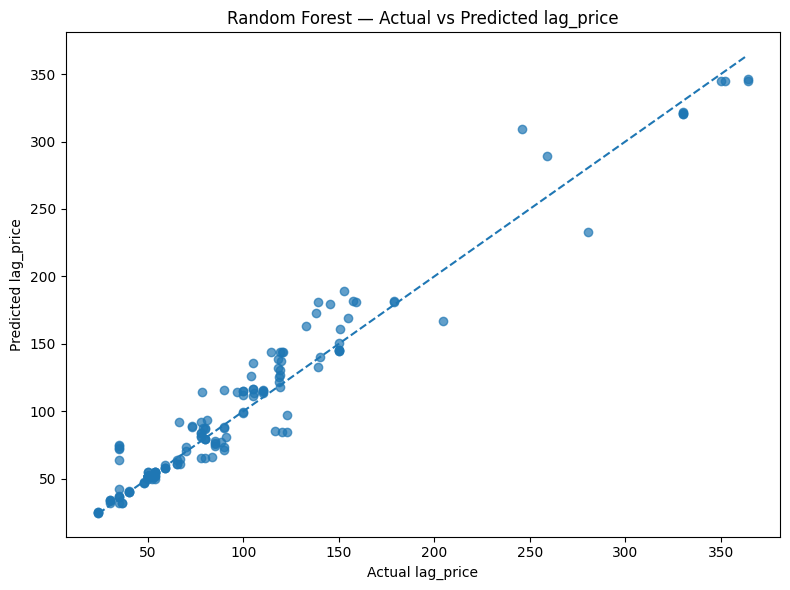

In [80]:
# ACTUAL VS PREDICTED

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    rf_predictions.min()
)

max_value = max(
    y_test.max(),
    rf_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual lag_price")
plt.ylabel("Predicted lag_price")
plt.title("Random Forest — Actual vs Predicted lag_price")

plt.tight_layout()
plt.show()

In [81]:
# RESIDUAL ANALYSIS

rf_residuals = y_test - rf_predictions

print("Residual summary:")
display(
    pd.Series(rf_residuals).describe().to_frame("residual")
)

Residual summary:


,residual
count,160.0000
mean,-3.8601
std,15.6539
min,-63.6574
25%,-8.1093
50%,-1.4478
75%,2.0041
max,48.0956


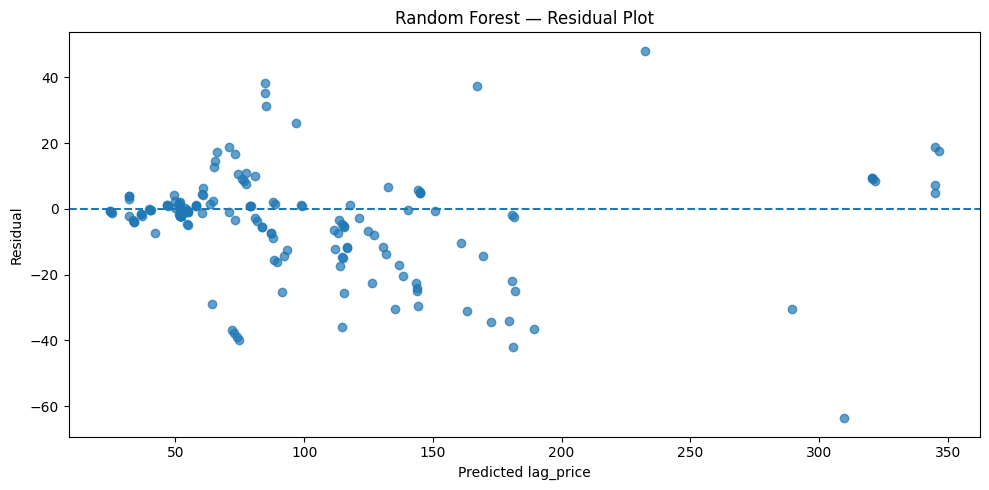

In [84]:
plt.figure(figsize=(10, 5))

plt.scatter(
    rf_predictions,
    rf_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted lag_price")
plt.ylabel("Residual")
plt.title("Random Forest — Residual Plot")

plt.tight_layout()
plt.show()

In [94]:

categorical_features = [
    "product_id",
    "product_category_name"
]

# ------------------------------------------------------------
# NUMERICAL FEATURES
# ------------------------------------------------------------

numerical_features = [
    # Time
    "month",
    "year",
    "quarter",
    "weekday",
    "weekend",
    "holiday",
    "time_index",
    "month_sin",
    "month_cos",

    # Product attributes
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_score",
    "volume",

    # Competitor prices
    "comp_1",
    "comp_2",
    "comp_3",
    "competitor_price_mean",
    "competitor_price_min",
    "competitor_price_max",

    # Competitor scores
    "ps1",
    "ps2",
    "ps3",
    "competitor_score_mean",
    "score_gap_vs_competitors",

    # Competitor freight
    "fp1",
    "fp2",
    "fp3",
    "competitor_freight_mean",

    # Seasonality
    "s"
]

# ------------------------------------------------------------
# NUMERICAL TRANSFORMER
# ------------------------------------------------------------

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# ------------------------------------------------------------
# CATEGORICAL TRANSFORMER
# ------------------------------------------------------------

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# ------------------------------------------------------------
# COLUMN TRANSFORMER
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


# XGB MODEL

In [ ]:
# xgboost model pipeline

from xgboost import XGBRegressor

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    
    ("model", XGBRegressor(
        n_estimators=800,
        learning_rate=0.06,
        max_depth=4,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.0,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)

In [210]:
# evaluate

xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_mse = mean_squared_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(xgb_mse)
xgb_mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
xgb_r2 = r2_score(y_test, y_pred_xgb)

print("XGBOOST REGRESSOR")
print("=" * 40)
print(f"MAE : {xgb_mae:.4f}")
print(f"MSE : {xgb_mse:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"MAPE: {xgb_mape:.4f}")
print(f"R²  : {xgb_r2:.4f}")

XGBOOST REGRESSOR
MAE : 9.3077
MSE : 249.6290
RMSE: 15.7997
MAPE: 0.1034
R²  : 0.9521


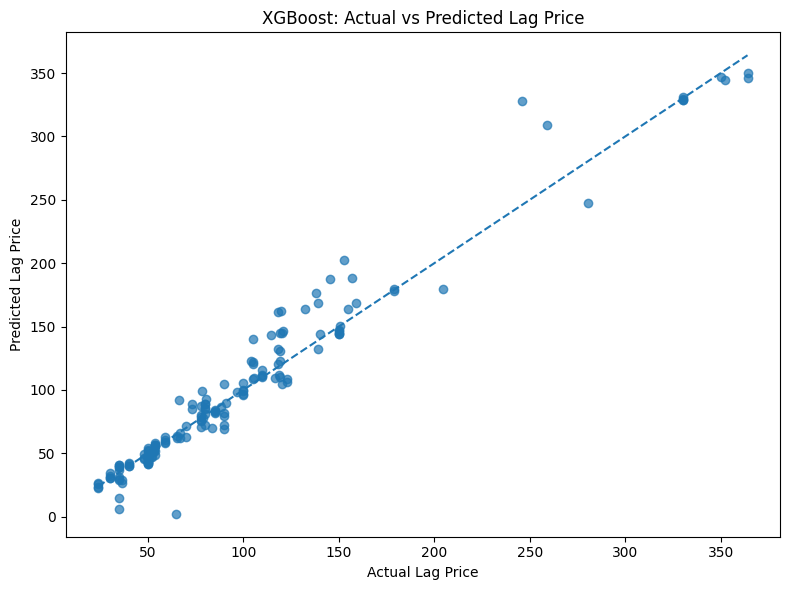

In [ ]:
# actual vs predicted plot for XGBoost

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Lag Price")
plt.ylabel("Predicted Lag Price")
plt.title("XGBoost: Actual vs Predicted Lag Price")

plt.tight_layout()
plt.show()

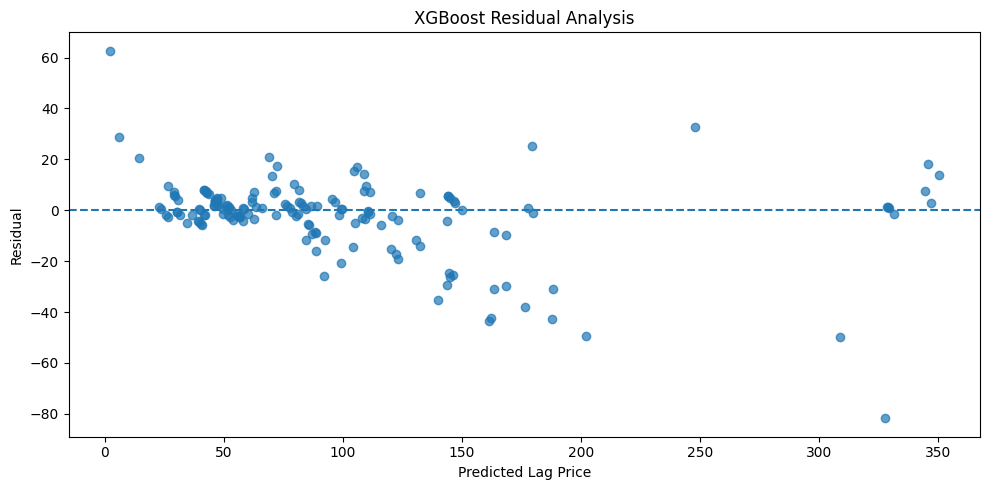

In [ ]:
# xgb residual analysis

xgb_residuals = y_test - y_pred_xgb

plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred_xgb,
    xgb_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Lag Price")
plt.ylabel("Residual")
plt.title("XGBoost Residual Analysis")

plt.tight_layout()
plt.show()

In [ ]:
# xgb residual summary statistics

display(
    pd.DataFrame({
        "Residual": xgb_residuals
    }).describe()
)

,Residual
count,160.0000
mean,-2.2575
std,15.6866
min,-81.7887
25%,-4.1848
50%,0.3532
75%,4.3567
max,62.6903


In [ ]:
# Decision Tree Regressor Pipeline

from sklearn.tree import DecisionTreeRegressor

dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

In [ ]:
#train the Decision Tree model

dt_model.fit(X_train, y_train)

print("Decision Tree model training completed.")

Decision Tree model training completed.


In [ ]:
y_pred_dt = dt_model.predict(X_test)

In [211]:
# evaluate the Decision Tree model

dt_mae = mean_absolute_error(y_test, y_pred_dt)
dt_mse = mean_squared_error(y_test, y_pred_dt)
dt_rmse = np.sqrt(dt_mse)
dt_mape = mean_absolute_percentage_error(y_test, y_pred_dt)
dt_r2 = r2_score(y_test, y_pred_dt)

print("DECISION TREE REGRESSOR")
print("=" * 40)
print(f"MAE : {dt_mae:.4f}")
print(f"MSE : {dt_mse:.4f}")
print(f"RMSE: {dt_rmse:.4f}")
print(f"MAPE: {dt_mape:.4f}")
print(f"R²  : {dt_r2:.4f}")

DECISION TREE REGRESSOR
MAE : 11.2187
MSE : 361.4482
RMSE: 19.0118
MAPE: 0.1463
R²  : 0.9307


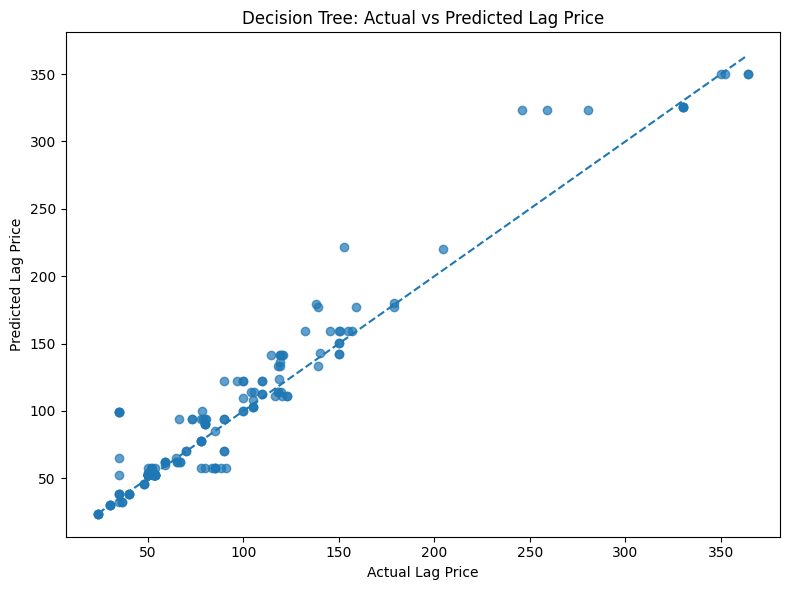

In [ ]:
# actual vs predicted plot for Decision Tree

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_dt,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Lag Price")
plt.ylabel("Predicted Lag Price")
plt.title("Decision Tree: Actual vs Predicted Lag Price")

plt.tight_layout()
plt.show()

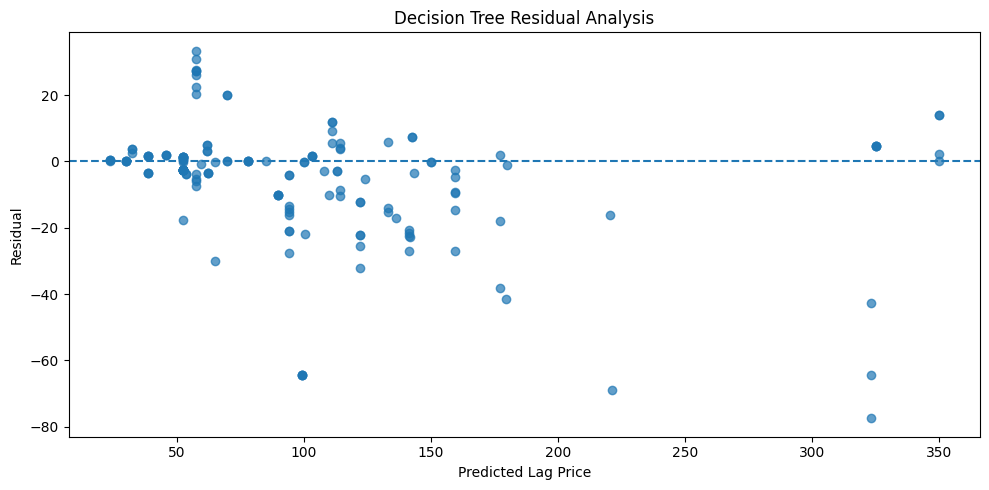

In [ ]:
# residual analysis for Decision Tree

dt_residuals = y_test - y_pred_dt

plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred_dt,
    dt_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Lag Price")
plt.ylabel("Residual")
plt.title("Decision Tree Residual Analysis")

plt.tight_layout()
plt.show()

In [ ]:
# residual summary statistics for Decision Tree

display(
    pd.DataFrame({
        "Residual": dt_residuals
    }).describe()
)

,Residual
count,160.0000
mean,-5.8077
std,18.1598
min,-77.4917
25%,-10.0225
50%,-2.6333
75%,1.7286
max,33.3687


In [ ]:
# RANDOM FOREST - RANDOMIZED SEARCH

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# ------------------------------------------------------------
# Random Forest Pipeline
# ------------------------------------------------------------

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# Parameter Grid
# ------------------------------------------------------------

rf_param_grid = {
    "model__n_estimators": [200, 300, 500, 700, 1000],
    "model__max_depth": [None, 5, 10, 15, 20, 25, 30],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8, 1.0]
}

# ------------------------------------------------------------
# Time Series Cross Validation
# ------------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=5)

# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# Fit
# ------------------------------------------------------------

rf_random_search.fit(X_train, y_train)

print("RANDOM FOREST - BEST PARAMETERS")
print("=" * 50)
print(rf_random_search.best_params_)

print("\nBest CV MAE:")
print(-rf_random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
RANDOM FOREST - BEST PARAMETERS
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 25}

Best CV MAE:
16.342103109769155


In [212]:
# tune the Random Forest model with the best parameters

best_rf = rf_random_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

rf_tuned_mae = mean_absolute_error(y_test,y_pred_rf_tuned)
rf_tuned_mse = mean_squared_error(y_test,y_pred_rf_tuned)
rf_tuned_rmse = np.sqrt(rf_tuned_mse)
rf_tuned_mape = mean_absolute_percentage_error(y_test,y_pred_rf_tuned)
rf_tuned_r2 = r2_score(y_test,y_pred_rf_tuned)

print("TUNED RANDOM FOREST")
print("=" * 40)
print(f"MAE : {rf_tuned_mae:.4f}")
print(f"MSE : {rf_tuned_mse:.4f}")
print(f"RMSE: {rf_tuned_rmse:.4f}")
print(f"MAPE: {rf_tuned_mape:.4f}")
print(f"R²  : {rf_tuned_r2:.4f}")

TUNED RANDOM FOREST
MAE : 9.8489
MSE : 229.7386
RMSE: 15.1571
MAPE: 0.1056
R²  : 0.9559


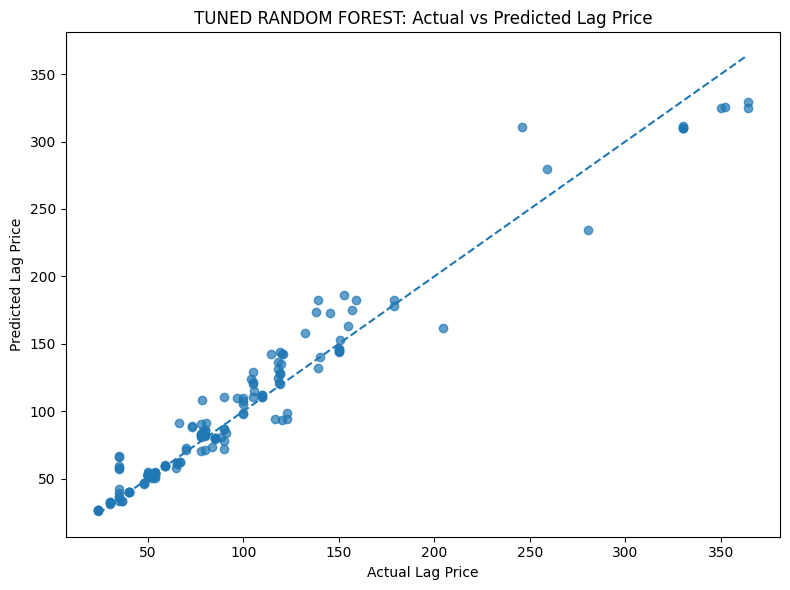

In [ ]:
# actual vs predicted plot for tuned Random Forest

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf_tuned,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Lag Price")
plt.ylabel("Predicted Lag Price")
plt.title("TUNED RANDOM FOREST: Actual vs Predicted Lag Price")

plt.tight_layout()
plt.show()

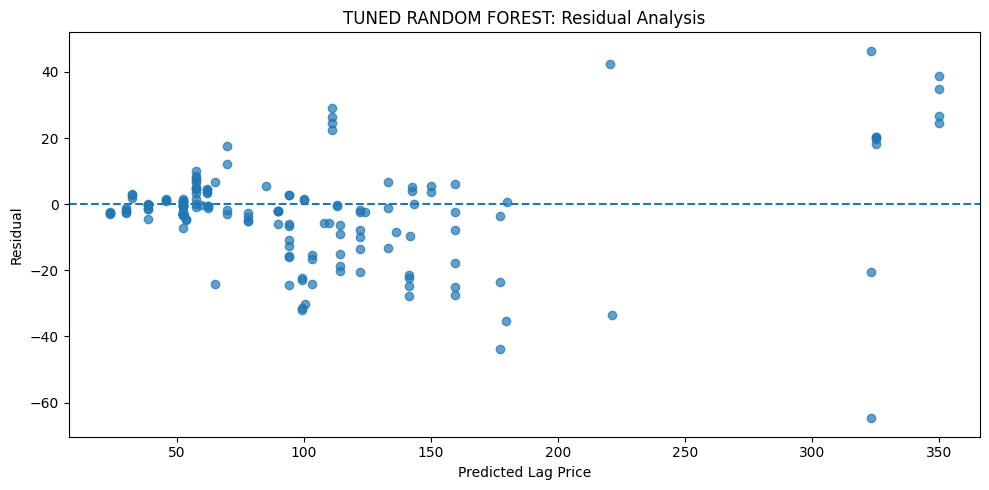

In [ ]:
# residual analysis for TUNED RANDOM FOREST

dt_residuals = y_test - y_pred_rf_tuned

plt.figure(figsize=(10, 5))

plt.scatter(
    y_pred_dt,
    dt_residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Lag Price")
plt.ylabel("Residual")
plt.title("TUNED RANDOM FOREST: Residual Analysis")

plt.tight_layout()
plt.show()

In [192]:
# xgboost - randomized search

from xgboost import XGBRegressor

# ------------------------------------------------------------
# XGBoost Pipeline
# ------------------------------------------------------------

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# Parameter Grid
# ------------------------------------------------------------

xgb_param_grid = {
    "model__n_estimators": [200, 300, 500, 700, 1000],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "model__max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, 20],
    "model__min_child_weight": [1, 2, 3, 5, 7],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__gamma": [0, 0.1, 0.2, 0.5],
    "model__reg_alpha": [0, 0.01, 0.1, 0.5],
    "model__reg_lambda": [1, 1.5, 2, 5]
}

# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# Fit
# ------------------------------------------------------------

xgb_random_search.fit(X_train, y_train)

print("XGBOOST - BEST PARAMETERS")
print("=" * 50)
print(xgb_random_search.best_params_)

print("\nBest CV MAE:")
print(-xgb_random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
XGBOOST - BEST PARAMETERS
{'model__subsample': 0.7, 'model__reg_lambda': 5, 'model__reg_alpha': 0.5, 'model__n_estimators': 1000, 'model__min_child_weight': 2, 'model__max_depth': 15, 'model__learning_rate': 0.03, 'model__gamma': 0, 'model__colsample_bytree': 1.0}

Best CV MAE:
14.496702945251622


In [214]:
# evaluate the tuned XGBoost model with the best parameters

best_xgb = xgb_random_search.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)

xgb_tuned_mae = mean_absolute_error(y_test,y_pred_xgb_tuned)
xgb_tuned_mse = mean_squared_error(y_test,y_pred_xgb_tuned)
xgb_tuned_rmse = np.sqrt(xgb_tuned_mse)
xgb_tuned_mape = mean_absolute_percentage_error(y_test,y_pred_xgb_tuned)
xgb_tuned_r2 = r2_score(y_test,y_pred_xgb_tuned)

print("TUNED XGBOOST")
print("=" * 40)
print(f"MAE : {xgb_tuned_mae:.4f}")
print(f"MSE : {xgb_tuned_mse:.4f}")
print(f"RMSE: {xgb_tuned_rmse:.4f}")
print(f"MAPE: {xgb_tuned_mape:.4f}")
print(f"R²  : {xgb_tuned_r2:.4f}")

TUNED XGBOOST
MAE : 10.1247
MSE : 282.0417
RMSE: 16.7941
MAPE: 0.1082
R²  : 0.9459


In [215]:
# final comparison of all models

tuned_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest - Before Tuning",
        "Random Forest - Tuned",
        "XGBoost - Before Tuning",
        "XGBoost - Tuned",
        "Decision Tree"
    ],
    "MAE": [
        ridge_mae,
        rf_mae,
        rf_tuned_mae,
        xgb_mae,
        xgb_tuned_mae,
        dt_mae
    ],
    "R²": [
        ridge_r2,
        rf_r2,
        rf_tuned_r2,
        xgb_r2,
        xgb_tuned_r2,
        dt_r2
    ]
})

tuned_comparison = tuned_comparison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(tuned_comparison)

,Model,MAE,R²
0,XGBoost - Before Tuning,9.3077,0.9521
1,Random Forest - Tuned,9.8489,0.9559
2,XGBoost - Tuned,10.1247,0.9459
3,Random Forest - Before Tuning,10.4236,0.9504
4,Decision Tree,11.2187,0.9307
5,Ridge Regression,11.5887,0.9311


In [216]:
# BEST MODEL

best_model_row = tuned_comparison.iloc[0]

print("BEST MODEL")
print("=" * 40)
print(f"Model : {best_model_row['Model']}")
print(f"MAE   : {best_model_row['MAE']:.4f}")
print(f"R²    : {best_model_row['R²']:.4f}")

BEST MODEL
Model : XGBoost - Before Tuning
MAE   : 9.3077
R²    : 0.9521


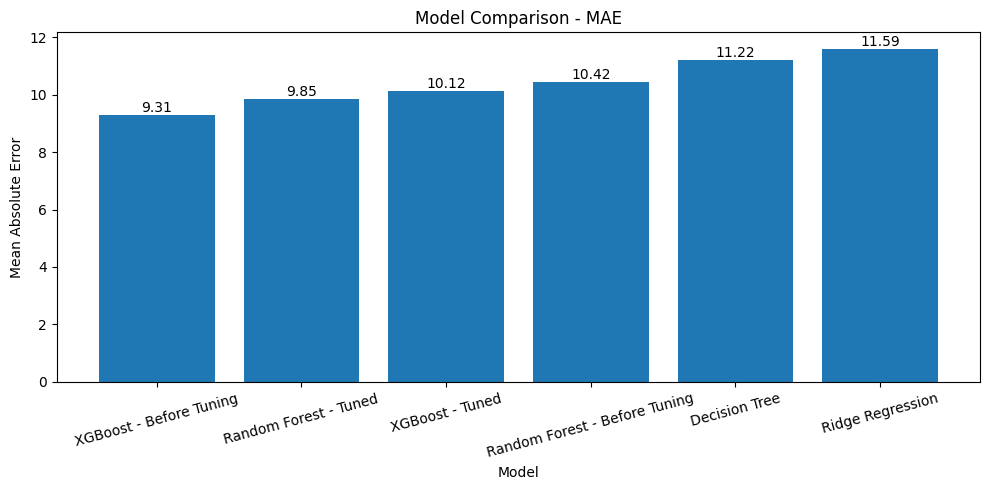

In [217]:
# plot the MAE comparison of all models

plt.figure(figsize=(10, 5))

bars = plt.bar(
    tuned_comparison["Model"],
    tuned_comparison["MAE"]
)

plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.title("Model Comparison - MAE")

plt.xticks(rotation=15)

for bar, value in zip(bars, tuned_comparison["MAE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

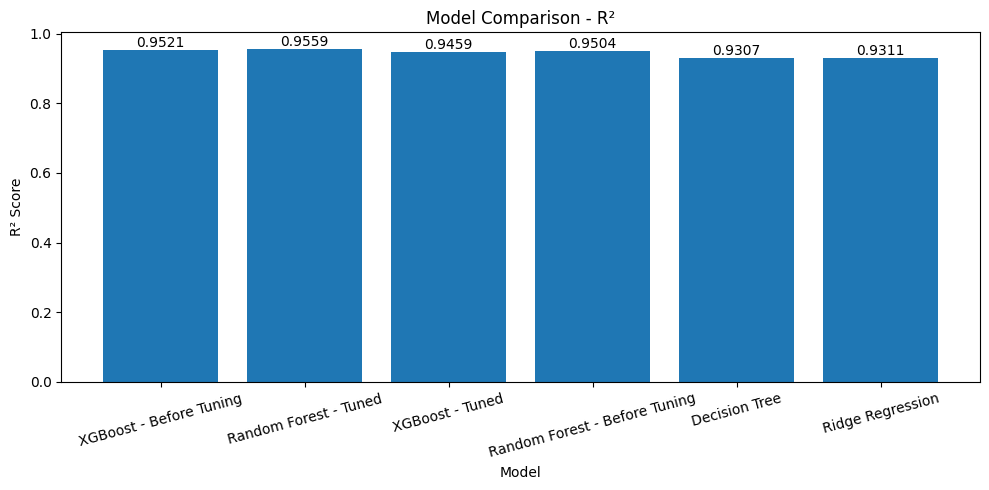

In [218]:
# ============================================================
# 50.2 R² COMPARISON
# ============================================================

plt.figure(figsize=(10, 5))

bars = plt.bar(
    tuned_comparison["Model"],
    tuned_comparison["R²"]
)

plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("Model Comparison - R²")

plt.xticks(rotation=15)

for bar, value in zip(bars, tuned_comparison["R²"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [219]:
# BEST MODEL

best_model_row = tuned_comparison.iloc[0]

print("BEST MODEL")
print("=" * 40)
print(f"Model : {best_model_row['Model']}")
print(f"MAE   : {best_model_row['MAE']:.4f}")
print(f"R²    : {best_model_row['R²']:.4f}")

BEST MODEL
Model : XGBoost - Before Tuning
MAE   : 9.3077
R²    : 0.9521


In [220]:
# ============================================================
# 52. PREDICTION COMPARISON
# ============================================================

prediction_comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Ridge": ridge_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": y_pred_xgb,
    "Decision Tree": y_pred_dt,
    "Random Forest Tuned": y_pred_rf_tuned,
    "XGBoost Tuned": y_pred_xgb_tuned
})

display(prediction_comparison.head(20))

,Actual,Ridge,Random Forest,XGBoost,Decision Tree,Random Forest Tuned,XGBoost Tuned
0,149.9000,155.1441,144.2962,144.1583,150.1148,144.4077,145.7707
1,110.0000,113.6074,115.5838,115.8707,112.9189,110.4278,115.9942
2,150.3423,216.9307,160.7725,150.1987,159.6892,152.8273,130.4224
3,349.9000,347.1133,345.1203,347.1010,349.9000,325.2558,345.4608
4,179.0000,183.8630,181.4567,177.9282,179.9775,178.3041,177.6112
5,23.9400,25.9756,25.2040,25.6750,23.6937,26.5137,23.6166
6,39.9900,49.3783,39.8826,41.8136,38.5142,40.0887,39.8842
7,105.6486,143.5912,113.0961,109.2206,114.2603,114.7225,116.9400
8,35.0571,25.8173,32.0585,29.4420,32.5607,33.2996,31.6170
9,53.9000,62.4344,54.3841,56.3440,52.6302,54.3816,53.9533


# Permutation importance